<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_MembershipInference_Tang2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Membership inference against a quantum neural network under quantum-native access: Tang, Joshi and Kundu (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Liou Tang, James Joshi and Ashish Kundu,
> "Characterizing Privacy Risks of Quantum Machine Learning with Emergent Quantum-Native Access",
> arXiv:2609.05702v2 [quant-ph], 9 September 2026. https://doi.org/10.48550/arxiv.2609.05702

The paper publishes no code; everything below is written from the method it describes, with the software it names
(PennyLane for the circuits, MNIST for the data). All quantum computations are exact classical simulations on a CPU: no
quantum hardware or cloud account is needed, and the paper itself uses none (it is "4-qubit, 24-parameter, noiseless simulation").

**The story in five sentences.** A machine-learning model can leak whether a particular example was in its training set
(a *membership inference attack*, MIA). Earlier work on quantum neural networks (QNNs) assumed the attacker only sees classical
measurement results, such as the label that comes out of a fixed read-out. The paper asks what changes if the attacker is a
*quantum* machine that may (M) choose its own Pauli measurement, or even (Q) receive the QNN's pre-measurement quantum state
itself. It proves that the best possible attack advantage obeys a hierarchy C <= M <= Q, that more shots *k* help, and that an attacker who
trains only *K* shadow models falls short of the information-theoretic optimum by a gap that shrinks with *K*. The experiments
use a 4-qubit, 24-parameter QNN on two binary MNIST tasks ("0" vs "1" and "3" vs "8") to illustrate these three claims.

**What the notebook does.**
1. Downloads MNIST, builds the two binary tasks, fits PCA (4 components) and scales the features to rotation angles.
2. Builds the paper's QNN (Fig. 1) as a batched exact simulator, checks it against PennyLane gate by gate, and draws the executed circuits with `qml.draw_mpl`.
3. Trains the *target and surrogate* models in the paper's "two worlds" design: pairs of models, one trained with a given data point and one without.
4. Implements the three attackers exactly: C_k (fixed read-out Z on qubit 0, optimal test on shot counts), M_k (best of the 255 Pauli-string measurements) and Q_k (the Helstrom measurement on k copies of the state, computed exactly from a Gram matrix, no sampling).
5. Redraws the paper's Fig. 2 (advantage versus shots k and versus number of surrogate pairs K), Fig. 3 (advantage versus Pauli weight) and Fig. 4 (gap between "theory" and empirical advantage versus K).
6. Adds what the paper does not: an honest *held-out* advantage on fresh target models, and a classical baseline (a loss/confidence-threshold attack on the QNN and on logistic regression, random forest and an RBF SVM trained on the same inputs).
7. Prints the paper's claims next to the notebook's numbers with a verdict for each.

**How to run.** Colab: Runtime -> Change runtime type -> CPU, then Runtime -> Run all. `FAST_MODE = True` runs a scaled-down version in about ten minutes; `FAST_MODE = False` follows the paper's
budgets (512-point population, 80 epochs, up to K = 128 surrogate pairs, k up to 32 shots) in roughly 50 minutes on a laptop CPU.
Nothing is read from your Google Drive; MNIST is downloaded into the working directory (about 11 MB).

## The paper in one page

**Problem.** Do QML models leak membership of their training data more if the attacker has *quantum* access? Prior work
(Heredge et al. 2025, Su et al. 2026) takes a classical attacker who sees classical read-out outcomes.

**Membership inference game (Game 1).** For a target point z = (x, y), a challenger trains a model on a data set that contains z
(b = 1) or does not (b = 0), and the attacker must guess b. The *advantage* is L = 2 Pr[correct] - 1 (so L = 1 is a perfect attack).

**Three access regimes (Table I)** for a QNN with pre-measurement state rho_theta(x) = U(theta) U_enc(x) |0..0><0..0| U_enc(x)^dagger U(theta)^dagger:

| Regime | What the attacker gets | Optimal advantage (Theorem III.2) |
|---|---|---|
| C_k classical outcomes | k shots of the *fixed* read-out Z on qubit 0 (`ZIII`) | total variation distance between the two outcome distributions |
| M_k programmable measurement | k shots of a Pauli measurement of the attacker's choice | supremum of that distance over the allowed measurements |
| Q_k quantum state | k copies of rho_theta(x) itself | Helstrom: half the trace norm of the difference of the two (model-averaged) k-copy states |

**Claims.**
(i) Theorem III.1: with classical outcomes a quantum attacker is no better than a classical one.
(ii) Theorem III.2: L_C <= L_M <= L_Q, and advantages never decrease with the number of shots k (Observation 2).
(iii) Theorem III.3 / Corollary III.4: an attacker with only K surrogate model pairs reaches an empirical advantage that falls short of the optimum by a gap eps bounded by the distance between the empirical and the true model-averaged states, E[eps] <= sqrt(2 d^k / K).
(iv) Experiments (Figs. 2-4): MNIST "0 vs 1" and "3 vs 8", 4 qubits, 3 variational layers, 24 parameters, k in {1,2,4,8,16,32}, K in {8,16,32,64} (and up to 256 for the gap), 512-point population, 256 training points per model, 80 epochs of Adam (lr 0.05, BCE loss, initialisation scale 0.2).
They show the hierarchy, that advantage grows with k, that richer Pauli measurements help (Fig. 3), and that the gap decays with K faster than K^(-1/2) (Fig. 4).

**What the paper does not give.** It reports its results only as plots (no numbers in the text), so numerical comparison is not possible; the notebook checks every *qualitative* claim and says "cannot be checked" for the plotted values.
The dataset hints in the repository index (ROAD, IBM hardware) come from the reference list; the experiments use MNIST only and simulation only.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST, "0 vs 1" and "3 vs 8", pixels in [-1, 1], PCA, top-4 components | same; MNIST from the public `mnist.npz` mirror (fallbacks: Hugging Face `ylecun/mnist`, OpenML) |
| PCA fitting set | not stated | **CHOICE:** PCA and the [-1, 1] scaling are fitted on a *public reference set* of 2000 MNIST training images of the two classes that is disjoint from the population, so the feature map does not depend on membership |
| Feature scale | RY(pi x_i) | the 4 PCA scores are divided by their largest absolute value on the reference set and clipped to [-1, 1] (**CHOICE**) |
| Circuit | Fig. 1: RY(pi x_i); 3 layers of RY, RZ on every qubit, ring of CNOT; 24 angles; read-out `ZIII` | same; ring = CNOT(0,1), CNOT(1,2), CNOT(2,3), CNOT(3,0) (**CHOICE** of direction) |
| Output and loss | expectation of Z on qubit 0, binary cross-entropy | probability of class 1 = (1 - <Z0>) / 2 (**CHOICE** of sign convention), BCE |
| Training | 80 epochs, Adam, lr 5e-2, init scale 0.2 | same; init normal(0, 0.2) and **mini-batch 32** (**CHOICE**: batch size not stated) |
| Population and surrogate sets | 512 points; |D| = 256 per model; K pairs of surrogate models | 512 points; each *pair* is trained on a random half and on its complement, so every target z is a member of exactly one model of each pair (**CHOICE**) and K pairs give exactly K "in" and K "out" models for every z |
| Shots and budgets | k in {1,2,4,8,16,32}; K in {8,16,32,64}; gap: K up to 256 | same k; K in {8,...,64} for Figs. 2-3; gap up to K = 128 (**CHOICE**, CPU time) |
| C_k attacker | "optimal subset of possible `ZIII` counts" | exact likelihood-ratio test on the shot count n (binomial mixtures), i.e. the total variation distance |
| M_k attacker | 255 Pauli strings of {X,Y,Z,I}^4 | one Pauli string measured k times gives k outcomes of +1 or -1 (**CHOICE**: the string's eigenvalue, not the individual qubit bits); best string chosen per target z; also grouped by Pauli weight 1..4 (Fig. 3) |
| Q_k attacker | "empirical Helstrom measurement" | exact: Helstrom on the model-averaged k-copy states, computed from the Gram matrix of the 2K pure states (no 16^k-dimensional matrices) |
| Target points | all 512 population points | 128 random population points (`N_Z`; FAST: 64); means and standard errors are over these (**CHOICE**, CPU time) |\n| "Theoretical" advantage L | exact optimum (needs the infinite model population) | **CHOICE:** proxy from an *independent* ensemble of K_ref = 128 pairs, same estimator |
| Empirical advantage | plug-in total variation / trace distance of the K-model averages (Eq. 32) | same plug-in (called *in-sample* below) **plus** an out-of-sample version evaluated on fresh target models (not in the paper) |
| Hardware | none (simulation) | none; "IBM hardware" numbers: **cannot be checked** |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever PennyLane / autograd are missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("pennylane", "autograd") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    %pip install -q "pennylane==0.45.1" "autograd==1.8.0"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane / autograd already present; skipping pip install.")

PennyLane / autograd already present; skipping pip install.


### Configuration

Every tunable constant is here. `FAST_MODE = True` shrinks the ensembles (fewer surrogate pairs, fewer targets, fewer epochs) so the
whole notebook runs in about ten minutes; `FAST_MODE = False` follows the paper's budgets as far as a CPU allows
(**CHOICE**: K up to 128 instead of 256 in the gap study).

In [2]:
# ---------------- configuration ----------------
FAST_MODE = False         # True: class demo (about 10 minutes on a CPU). False: paper-size run (about 50 minutes on a CPU).
SEED      = 42            # CHOICE: the paper gives no seed
IBM_TOKEN = ""            # not used: the paper's experiments are noiseless simulations (kept for convention; no hardware cell here)
DATA_DIR  = "qc059_data"  # where MNIST is cached (relative to the working directory)

TASKS      = {"0 vs 1": (0, 1), "3 vs 8": (3, 8)}   # the paper's two binary MNIST tasks (second digit = label 1)
N_QUBITS, N_LAYERS = 4, 3                           # paper: 4 qubits, 3 variational layers, 24 angles
N_POP      = 512          # paper: 512 points sampled uniformly from the two classes = global population
N_TRAIN    = 256          # paper: |D| = |D_s| = 256 points per model
LR, INIT_SCALE = 5e-2, 0.2        # paper: Adam, lr 5e-2, init scale 0.2
BATCH      = 32           # CHOICE: mini-batch size (not stated in the paper)
N_REF_IMG  = 2000         # CHOICE: public reference images (disjoint from the population) used to fit PCA and the scaling
N_EVAL     = 1000         # held-out MNIST test images per task, only to report model accuracy
SHOT_LIST  = [1, 2, 4, 8, 16, 32]   # paper: k-shot measurement outcomes
GAP_SHOTS  = [2, 4, 8]              # paper Fig. 4 uses k = 2, 4, 8

if FAST_MODE:
    EPOCHS      = 20                  # paper: 80
    PAIRS_A     = 16                  # ensemble A: surrogate pairs of the attacker (paper: up to 256)
    PAIRS_R     = 16                  # ensemble R: independent reference pairs ("theory" proxy)
    PAIRS_T     = 8                   # ensemble T: fresh target pairs for the out-of-sample advantage
    K_LIST      = [4, 8, 16]          # surrogate budgets K (paper: 8, 16, 32, 64; gap up to 256)
    K_MAIN      = 16                  # K used for the k-sweeps and the held-out evaluation (paper: 64)
    N_Z         = 64                  # number of target points z evaluated (paper: all 512)
    PAIRS_CLS   = (8, 4)              # classical-baseline pairs (attacker's, target's)
else:
    EPOCHS      = 80
    PAIRS_A     = 128
    PAIRS_R     = 128
    PAIRS_T     = 64
    K_LIST      = [8, 16, 32, 64, 128]
    K_MAIN      = 64
    N_Z         = 128                 # CHOICE: target points z evaluated (paper: all 512; 128 random ones keep the run near 50 minutes)
    PAIRS_CLS   = (32, 16)
K_REF = max(K_LIST)               # size of the reference ensemble used as the "theoretical" optimum
assert PAIRS_A >= max(K_LIST) and PAIRS_R >= K_REF and K_MAIN in K_LIST

In [3]:
import os, time, warnings, itertools, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import autograd, autograd.numpy as anp
from autograd import value_and_grad
import scipy, scipy.special
import sklearn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
import pennylane as qml

# --- Hugging Face token: only needed if a gated dataset is used. MNIST is public, so this is just a fallback path. ---
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(SEED)          # every random draw below is derived from SEED
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__,
      "| pennylane", qml.__version__, "| autograd", importlib.metadata.version("autograd"))

numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | pennylane 0.45.1 | autograd 1.8.0


## 1. Data: two binary MNIST tasks reduced to four rotation angles

The paper uses two subsets of MNIST: "0 vs 1" (an easy pair) and "3 vs 8" (a hard pair). Following the paper, pixels are mapped to
[-1, 1] (28 x 28 = 784 features), a PCA keeps the top-4 components, and component *i* becomes the rotation angle pi * x_i of qubit *i*
(`RY(pi x_i)`), so the features must lie in [-1, 1].

Three disjoint sets of real MNIST images are drawn for each task:

* a **public reference set** (2000 images of the two classes from the MNIST training split), used only to fit the PCA and the scale factor
  (the feature map is public knowledge and must not depend on who is a member; **CHOICE**, the paper does not say where PCA is fitted);
* the **population** of 512 images, sampled uniformly from the two classes: every target point z that the attacker tries to attribute comes
  from here, and every model is trained on 256 of these 512 points;
* an **evaluation set** of 1000 MNIST test images, used only to report how accurate the QNNs are (not used by the attackers).

In [4]:
def load_mnist():
    """Return x_train (60000,28,28) uint8, y_train, x_test, y_test. Cached in DATA_DIR. Sources: Google mirror, Hugging Face, OpenML."""
    cache = os.path.join(DATA_DIR, "mnist.npz")
    if not os.path.exists(cache):
        try:
            import requests
            r = requests.get("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", timeout=120)
            r.raise_for_status()
            with open(cache, "wb") as f: f.write(r.content)
        except Exception as e1:
            print("primary MNIST mirror failed:", repr(e1)[:120])
            try:                                               # fallback 1: Hugging Face dataset ylecun/mnist (public parquet files)
                from huggingface_hub import hf_hub_download
                import io
                from PIL import Image
                out = {}
                for split in ("train", "test"):
                    fp = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset", token=HF_TOKEN or None)
                    df = pd.read_parquet(fp)
                    out["x_" + split] = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
                    out["y_" + split] = df["label"].to_numpy()
                np.savez_compressed(cache, **out)
            except Exception as e2:                            # fallback 2: OpenML
                print("Hugging Face fallback failed:", repr(e2)[:120])
                from sklearn.datasets import fetch_openml
                X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=os.path.join(DATA_DIR, "openml"))
                X = X.reshape(-1, 28, 28).astype(np.uint8); y = y.astype(int)
                np.savez_compressed(cache, x_train=X[:60000], y_train=y[:60000], x_test=X[60000:], y_test=y[60000:])
    z = np.load(cache)
    return z["x_train"], z["y_train"].astype(int), z["x_test"], z["y_test"].astype(int)

t0 = time.time()
X_TR, Y_TR, X_TE, Y_TE = load_mnist()
print(f"MNIST loaded in {time.time()-t0:.1f}s: train {X_TR.shape}, test {X_TE.shape}")

def pix(a):                       # pixels in [-1, 1], flattened, as in the paper
    return (a.reshape(len(a), -1).astype(np.float64) / 127.5) - 1.0

def make_task(name, digits, seed):
    """Reference / population / evaluation sets and the 4 angle features for one binary task. Everything is fitted on the reference set only."""
    r = np.random.default_rng(seed)
    d0, d1 = digits
    pool = np.flatnonzero(np.isin(Y_TR, digits)); r.shuffle(pool)
    ref_idx, pop_idx = pool[:N_REF_IMG], pool[N_REF_IMG:N_REF_IMG + N_POP]          # disjoint
    ev_pool = np.flatnonzero(np.isin(Y_TE, digits)); r.shuffle(ev_pool); ev_idx = ev_pool[:N_EVAL]
    pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(pix(X_TR[ref_idx]))      # CHOICE: public reference set
    scale = np.abs(pca.transform(pix(X_TR[ref_idx]))).max(0)                         # CHOICE: map each PC to [-1, 1]
    def feats(a): return np.clip(pca.transform(pix(a)) / scale, -1, 1)
    T = dict(name=name, digits=digits, pca=pca, scale=scale,
             img_pop=X_TR[pop_idx], digit_pop=Y_TR[pop_idx], y_pop=(Y_TR[pop_idx] == d1).astype(float),
             img_ref=X_TR[ref_idx], digit_ref=Y_TR[ref_idx],
             digit_ev=Y_TE[ev_idx], y_ev=(Y_TE[ev_idx] == d1).astype(float))
    T["x_pop"], T["x_ref"], T["x_ev"] = feats(X_TR[pop_idx]), feats(X_TR[ref_idx]), feats(X_TE[ev_idx])
    T["raw_pop"] = pca.transform(pix(X_TR[pop_idx]))                                 # un-scaled PCA scores, for the plots
    return T

TASK = {nm: make_task(nm, dg, SEED + i) for i, (nm, dg) in enumerate(TASKS.items())}
for nm, T in TASK.items():
    print(f"{nm}: reference {len(T['digit_ref'])}, population {len(T['digit_pop'])} (class balance {T['y_pop'].mean():.2f}), evaluation {len(T['y_ev'])}; "
          f"PCA explained variance of the 4 components: {np.round(T['pca'].explained_variance_ratio_, 3)}")

MNIST loaded in 0.5s: train (60000, 28, 28), test (10000, 28, 28)


0 vs 1: reference 2000, population 512 (class balance 0.51), evaluation 1000; PCA explained variance of the 4 components: [0.32  0.087 0.078 0.06 ]
3 vs 8: reference 2000, population 512 (class balance 0.48), evaluation 1000; PCA explained variance of the 4 components: [0.125 0.079 0.069 0.051]


## Dataset Exploration and Visualisation

The experiments use one real data set, MNIST handwritten digits (60 000 training and 10 000 test images of 28 x 28 pixels, ten digit classes),
restricted to the two binary tasks above. The cells below print its shape, feature names and class counts, plot the real class distribution,
show a few real images, and draw the 2-D scatter plots of the real observations (the 512-point population of each task) coloured by their
ground-truth digit: first the raw PCA coordinates (fitted on the public reference set), then the same coordinates as the rotation angles
pi * x_i that the circuit actually receives.

MNIST train: (60000, 28, 28) labels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | MNIST test: (10000, 28, 28)
original features: 784 pixels (pixel_0 ... pixel_783), integer grey levels 0..255, rescaled to [-1, 1] before PCA
model features   : ['PC1', 'PC2', 'PC3', 'PC4'] -> angles pi*x_1 ... pi*x_4 on qubits 0..3


digit,0,1,2,3,4,5,6,7,8,9
train images,5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
test images,980,1135,1032,1010,982,892,958,1028,974,1009


,label0,label1,population,n_label0,n_label1,reference,evaluation,x_pop_shape
task,,,,,,,,
0 vs 1,digit 0,digit 1,512,251,261,2000,1000,"(512, 4)"
3 vs 8,digit 3,digit 8,512,264,248,2000,1000,"(512, 4)"


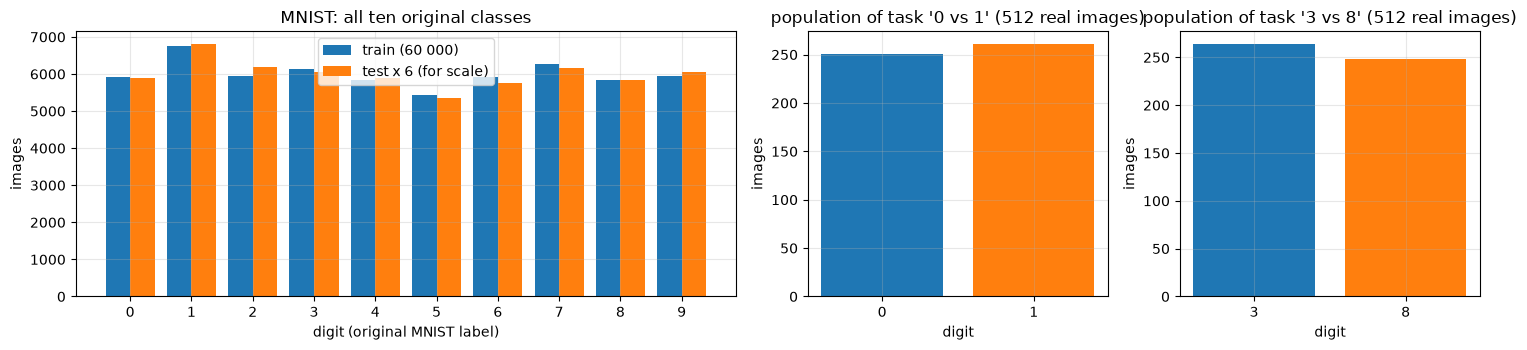

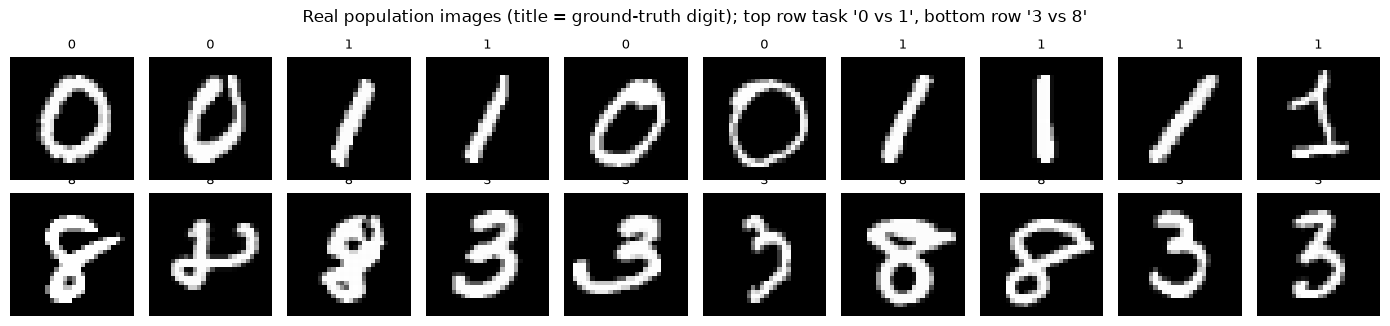

In [5]:
print("MNIST train:", X_TR.shape, "labels", np.unique(Y_TR).tolist(), "| MNIST test:", X_TE.shape)
print("original features: 784 pixels (pixel_0 ... pixel_783), integer grey levels 0..255, rescaled to [-1, 1] before PCA")
print("model features   :", ["PC1", "PC2", "PC3", "PC4"], "-> angles pi*x_1 ... pi*x_4 on qubits 0..3")
cnt_tr, cnt_te = np.bincount(Y_TR, minlength=10), np.bincount(Y_TE, minlength=10)
display(pd.DataFrame({"digit": range(10), "train images": cnt_tr, "test images": cnt_te}).set_index("digit").T)
rows = []
for nm, T in TASK.items():
    d0, d1 = T["digits"]
    rows.append(dict(task=nm, label0=f"digit {d0}", label1=f"digit {d1}",
                     population=len(T["y_pop"]), n_label0=int((T["y_pop"] == 0).sum()), n_label1=int((T["y_pop"] == 1).sum()),
                     reference=len(T["digit_ref"]), evaluation=len(T["y_ev"]), x_pop_shape=T["x_pop"].shape))
display(pd.DataFrame(rows).set_index("task"))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[2.2, 1, 1]))
w = 0.4; dd = np.arange(10)
axes[0].bar(dd - w/2, cnt_tr, w, label="train (60 000)"); axes[0].bar(dd + w/2, cnt_te * 6, w, label="test x 6 (for scale)")
axes[0].set_xticks(dd); axes[0].set_xlabel("digit (original MNIST label)"); axes[0].set_ylabel("images"); axes[0].set_title("MNIST: all ten original classes"); axes[0].legend()
for ax, (nm, T) in zip(axes[1:], TASK.items()):
    d0, d1 = T["digits"]
    ax.bar([f"{d0}", f"{d1}"], [(T["digit_pop"] == d0).sum(), (T["digit_pop"] == d1).sum()], color=["tab:blue", "tab:orange"])
    ax.set_title(f"population of task '{nm}' (512 real images)"); ax.set_xlabel("digit"); ax.set_ylabel("images")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 10, figsize=(14, 3.3))
for r_, (nm, T) in enumerate(TASK.items()):
    for c_ in range(10):
        axes[r_, c_].imshow(T["img_pop"][c_], cmap="gray"); axes[r_, c_].axis("off"); axes[r_, c_].set_title(f"{T['digit_pop'][c_]}", fontsize=9)
fig.suptitle("Real population images (title = ground-truth digit); top row task '0 vs 1', bottom row '3 vs 8'"); plt.tight_layout(); plt.show()

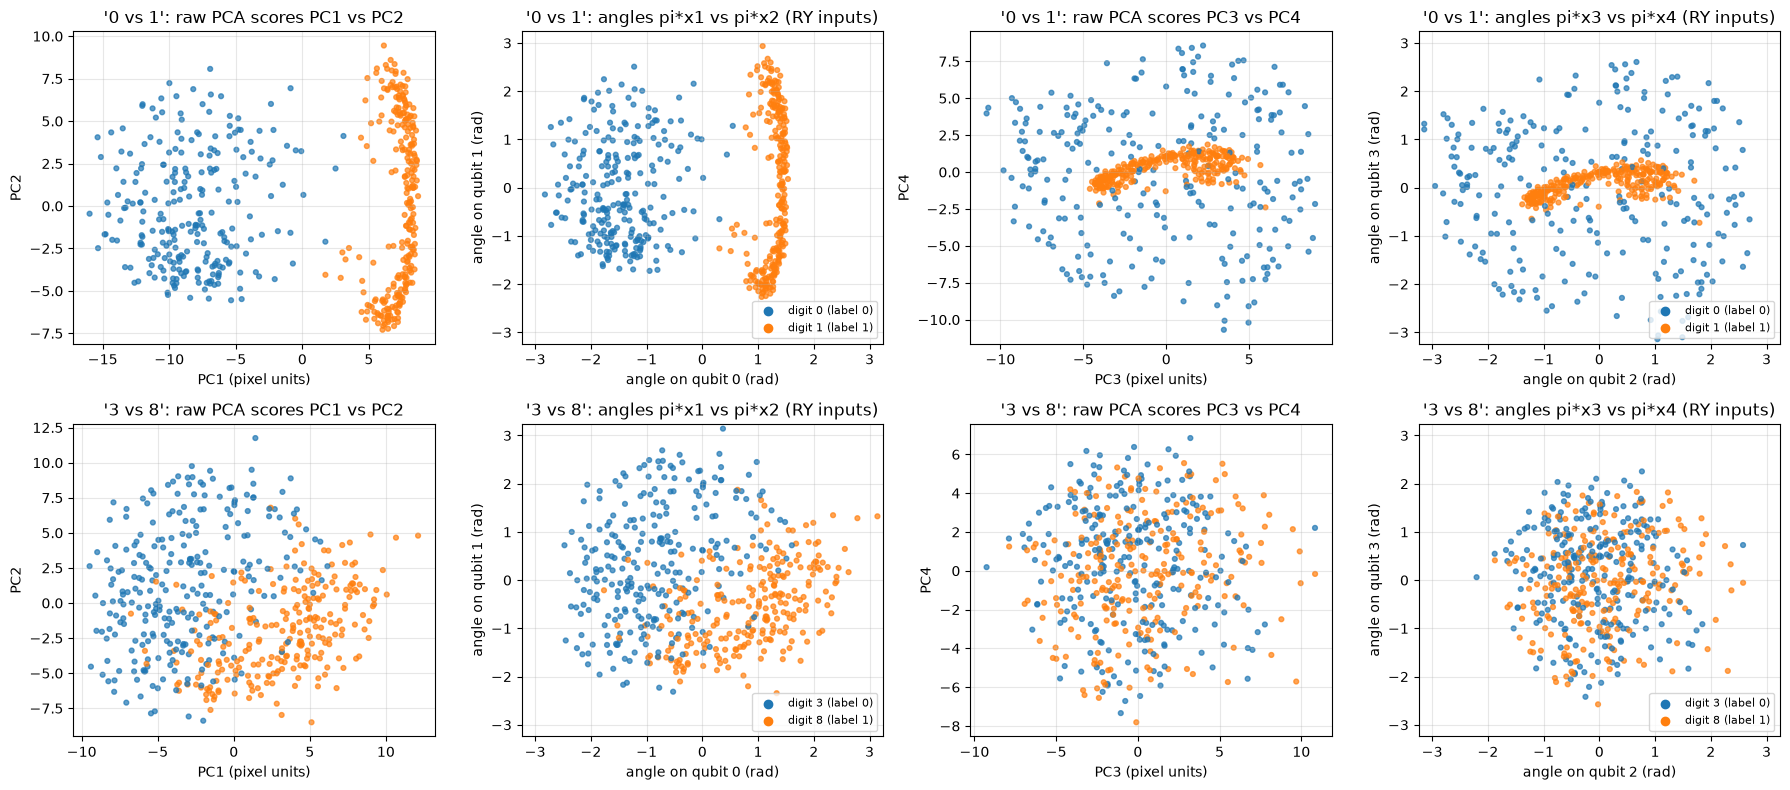

'0 vs 1': a 5-NN classifier on the same 4 angles scores 1.000 on the population (an easy pair separates well in 4 PCA dimensions; the hard pair '3 vs 8' overlaps, which is why the QNN overfits less there).
'3 vs 8': a 5-NN classifier on the same 4 angles scores 0.871 on the population (an easy pair separates well in 4 PCA dimensions; the hard pair '3 vs 8' overlaps, which is why the QNN overfits less there).


In [6]:
# 2-D scatter of the real population, coloured by ground-truth digit. Raw PCA coordinates (fitted on the reference set), then the angles pi*x
# that the circuit receives (angle encoding RY(pi x_i)).
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for r_, (nm, T) in enumerate(TASK.items()):
    d0, d1 = T["digits"]; col = np.where(T["digit_pop"] == d0, "tab:blue", "tab:orange")
    for j, (a, b) in enumerate([(0, 1), (2, 3)]):
        ax = axes[r_, 2 * j]
        ax.scatter(T["raw_pop"][:, a], T["raw_pop"][:, b], c=col, s=12, alpha=0.7)
        ax.set_title(f"'{nm}': raw PCA scores PC{a+1} vs PC{b+1}"); ax.set_xlabel(f"PC{a+1} (pixel units)"); ax.set_ylabel(f"PC{b+1}")
        ax = axes[r_, 2 * j + 1]
        ax.scatter(np.pi * T["x_pop"][:, a], np.pi * T["x_pop"][:, b], c=col, s=12, alpha=0.7)
        ax.set_title(f"'{nm}': angles pi*x{a+1} vs pi*x{b+1} (RY inputs)"); ax.set_xlabel(f"angle on qubit {a} (rad)"); ax.set_ylabel(f"angle on qubit {b} (rad)")
        ax.set_xlim(-np.pi - .1, np.pi + .1); ax.set_ylim(-np.pi - .1, np.pi + .1)
        ax.scatter([], [], c="tab:blue", label=f"digit {d0} (label 0)"); ax.scatter([], [], c="tab:orange", label=f"digit {d1} (label 1)"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
for nm, T in TASK.items():
    from sklearn.neighbors import KNeighborsClassifier
    knn = KNeighborsClassifier(5).fit(T["x_ref"], (T["digit_ref"] == T["digits"][1]).astype(int))
    print(f"'{nm}': a 5-NN classifier on the same 4 angles scores {knn.score(T['x_pop'], T['y_pop']):.3f} on the population "
          f"(an easy pair separates well in 4 PCA dimensions; the hard pair '3 vs 8' overlaps, which is why the QNN overfits less there).")

## 2. The target and surrogate QNN, and a fast exact simulator for it

Fig. 1 of the paper: four qubits; the features enter as `RY(pi x_i)`; then three variational layers, each with `RY` and `RZ` on every qubit followed by a ring of
CNOTs (24 trainable angles); the prediction is the expectation of Pauli-Z on qubit 0 (`ZIII`).

The study needs **hundreds of trained models** (every target point needs K "in" and K "out" models, for several K). PennyLane's own simulator trains
one model at a time; here a model is a 16 x 16 unitary, so we write *the same circuit* as batched linear algebra (`autograd` provides the gradients) and train
all models of an ensemble together. The circuit-drawing section right below asserts that this simulator and PennyLane's `default.qubit` agree to floating-point accuracy
on the expectation values of all Pauli strings and on the full state vector, so what is simulated is exactly the circuit that is drawn.

Conventions (as in PennyLane): wire 0 is the most significant bit of the basis-state index; `RY(a) = exp(-i a Y / 2)`, `RZ(b) = exp(-i b Z / 2)`.

In [7]:
NQ, NL, DIM = N_QUBITS, N_LAYERS, 2 ** N_QUBITS

def _cnot_ring_perm():
    """Index permutation of the CNOT ring CNOT(0,1), CNOT(1,2), CNOT(2,3), CNOT(3,0): new_state[j] = old_state[perm[j]]."""
    bits = lambda k: [(k >> (NQ - 1 - q)) & 1 for q in range(NQ)]
    idx_of = lambda b: sum(bit << (NQ - 1 - q) for q, bit in enumerate(b))
    dest = np.zeros(DIM, dtype=int)
    for k in range(DIM):
        b = bits(k)
        for i in range(NQ):
            if b[i]: b[(i + 1) % NQ] ^= 1          # CHOICE: ring direction i -> i+1
        dest[k] = idx_of(b)
    perm = np.zeros(DIM, dtype=int); perm[dest] = np.arange(DIM)
    return perm
PERM = _cnot_ring_perm()
ZSIGN = np.array([1 - 2 * ((k >> (NQ - 1)) & 1) for k in range(DIM)], float)       # eigenvalues of Z on wire 0 (ZIII)

def layer_unitary(th):
    """th (M, 4, 2): [:, q, 0] = RY angle, [:, q, 1] = RZ angle. Returns (M, 16, 16) = kron_q RZ(b_q) RY(a_q) (RY first, then RZ, as in Fig. 1)."""
    a, b = th[..., 0], th[..., 1]
    c, s = anp.cos(a / 2), anp.sin(a / 2)
    em, ep = anp.exp(-0.5j * b), anp.exp(0.5j * b)
    R = anp.stack([anp.stack([em * c, -em * s], -1), anp.stack([ep * s, ep * c], -1)], -2)       # (M, 4, 2, 2)
    K = R[:, 0]
    for q in range(1, NQ):
        K = anp.einsum('mab,mcd->macbd', K, R[:, q]); n = K.shape[1] * K.shape[2]; K = K.reshape(K.shape[0], n, n)
    return K

def model_unitaries(theta):
    """theta (M, 3, 4, 2) -> U (M, 16, 16) of the variational part: layer = (RY, RZ on every qubit) then the CNOT ring."""
    U = None
    for l in range(NL):
        K = layer_unitary(theta[:, l])
        U = K if U is None else anp.matmul(K, U)
        U = U[:, PERM, :]
    return U

def encode(x):
    """x (..., 4) in [-1, 1] -> real 16-vector of  prod_q RY(pi x_q)|0>  (the encoding state, a product state)."""
    v = np.stack([np.cos(np.pi * x / 2), np.sin(np.pi * x / 2)], -1)
    out = v[..., 0, :]
    for q in range(1, NQ):
        out = np.einsum('...a,...b->...ab', out, v[..., q, :]).reshape(*out.shape[:-1], -1)
    return out

def batch_loss(theta_flat, Phi, y):
    """Sum over models of the mean binary cross-entropy. Phi (M, B, 16) encoded inputs, y (M, B) labels.  f = <Z_0>,  p(class 1) = (1 - f) / 2."""
    M = Phi.shape[0]
    U = model_unitaries(theta_flat.reshape(M, NL, NQ, 2))
    Ur, Ui = anp.real(U), anp.imag(U)
    O = anp.einsum('mji,j,mjk->mik', Ur, ZSIGN, Ur) + anp.einsum('mji,j,mjk->mik', Ui, ZSIGN, Ui)     # Re(U^dagger Z0 U); Phi is real
    f = anp.einsum('mbi,mik,mbk->mb', Phi, O, Phi)
    p = anp.clip((1 - f) / 2, 1e-7, 1 - 1e-7)
    return anp.sum(anp.mean(-(y * anp.log(p) + (1 - y) * anp.log(1 - p)), 1))
_vg = value_and_grad(batch_loss)
print("simulator ready: 16 x 16 unitaries, 24 trainable angles per model")

simulator ready: 16 x 16 unitaries, 24 trainable angles per model


## Quantum Circuit Architecture

Three PennyLane QNodes share the circuit of the paper's Fig. 1 and differ only in what the attacker receives. They are the circuits that the experiments evaluate:

* **Victim, regime C_k**: the QNN returns the expectation of `ZIII` (shots of the fixed read-out).
* **Attack circuit, regime M_k**: the same QNN, but the attacker chooses the measurement. Shown for one example Pauli string, `X Y Z X` (weight 4); the notebook evaluates all 255 strings.
* **Attack circuit, regime Q_k**: the QNN hands over its pre-measurement state `rho_theta(x)` (`qml.state()`); the attacker's Helstrom measurement acts collectively on k copies of that state.
  It is a measurement in an entangled basis of the k copies, computed here exactly and classically, so it is not a gate sequence of the circuit drawn.

Assumptions where the paper is silent: the order inside a layer (RY then RZ, from the gate order in Fig. 1), the direction of the CNOT ring (0->1->2->3->0), and the weights are random angles
(here shown for one draw of the initial parameters).

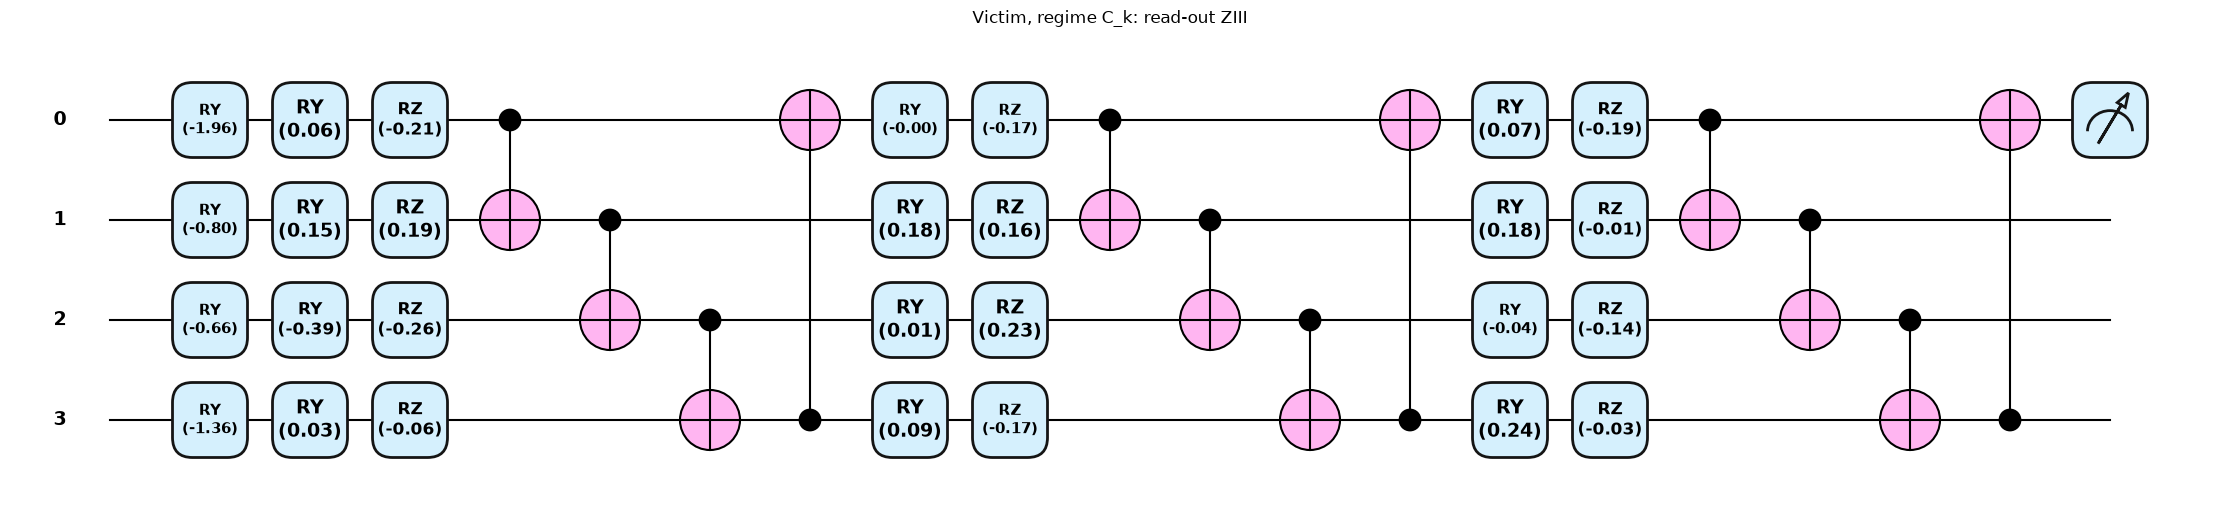

Victim, regime C_k: read-out ZIII: qubits = 4, circuit depth = 19, trainable angles = 24  (RY + RZ on 4 qubits x 3 layers); encoding gates RY(pi x_i): 4; CNOTs: 12


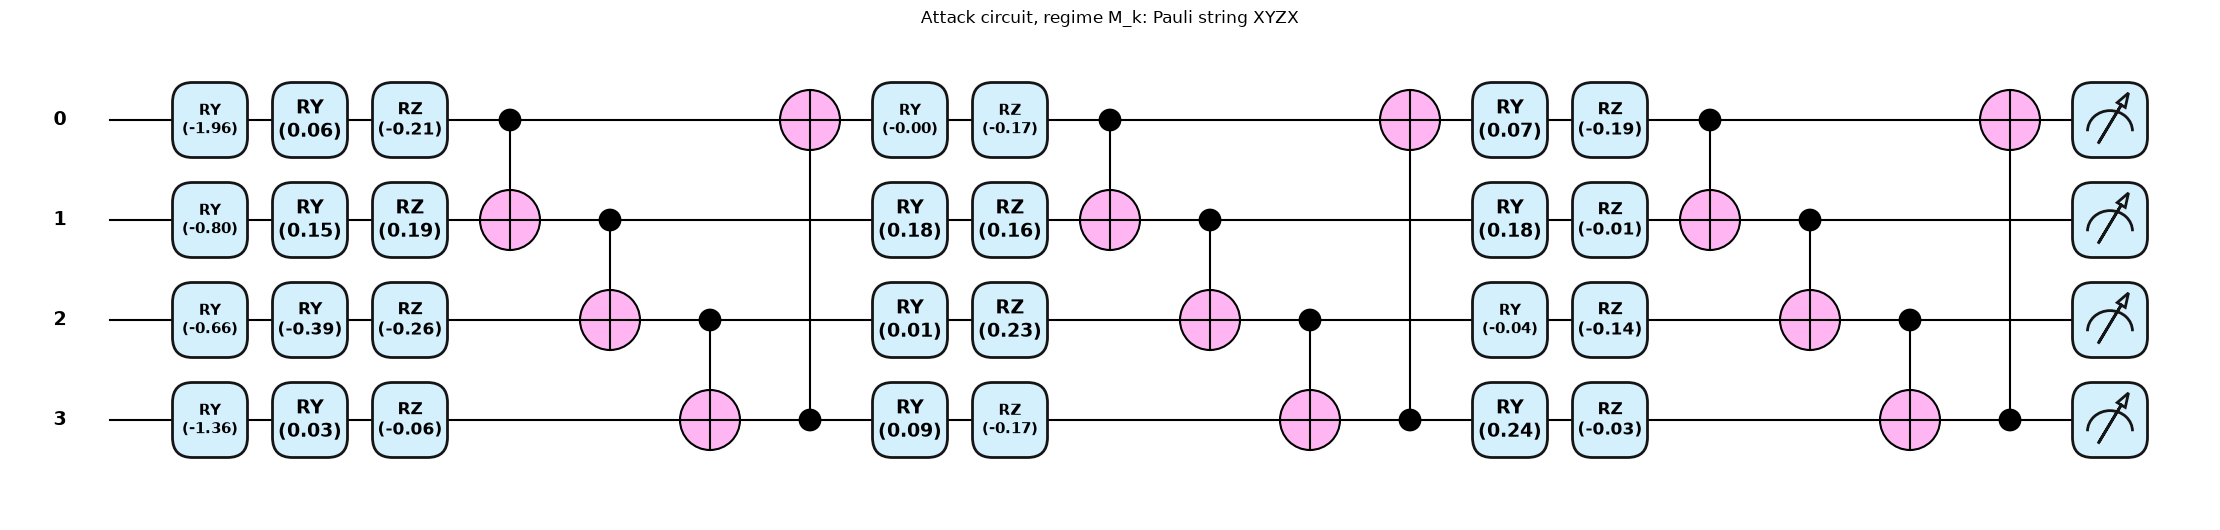

Attack circuit, regime M_k: Pauli string XYZX: qubits = 4, circuit depth = 19, trainable angles = 24  (RY + RZ on 4 qubits x 3 layers); encoding gates RY(pi x_i): 4; CNOTs: 12


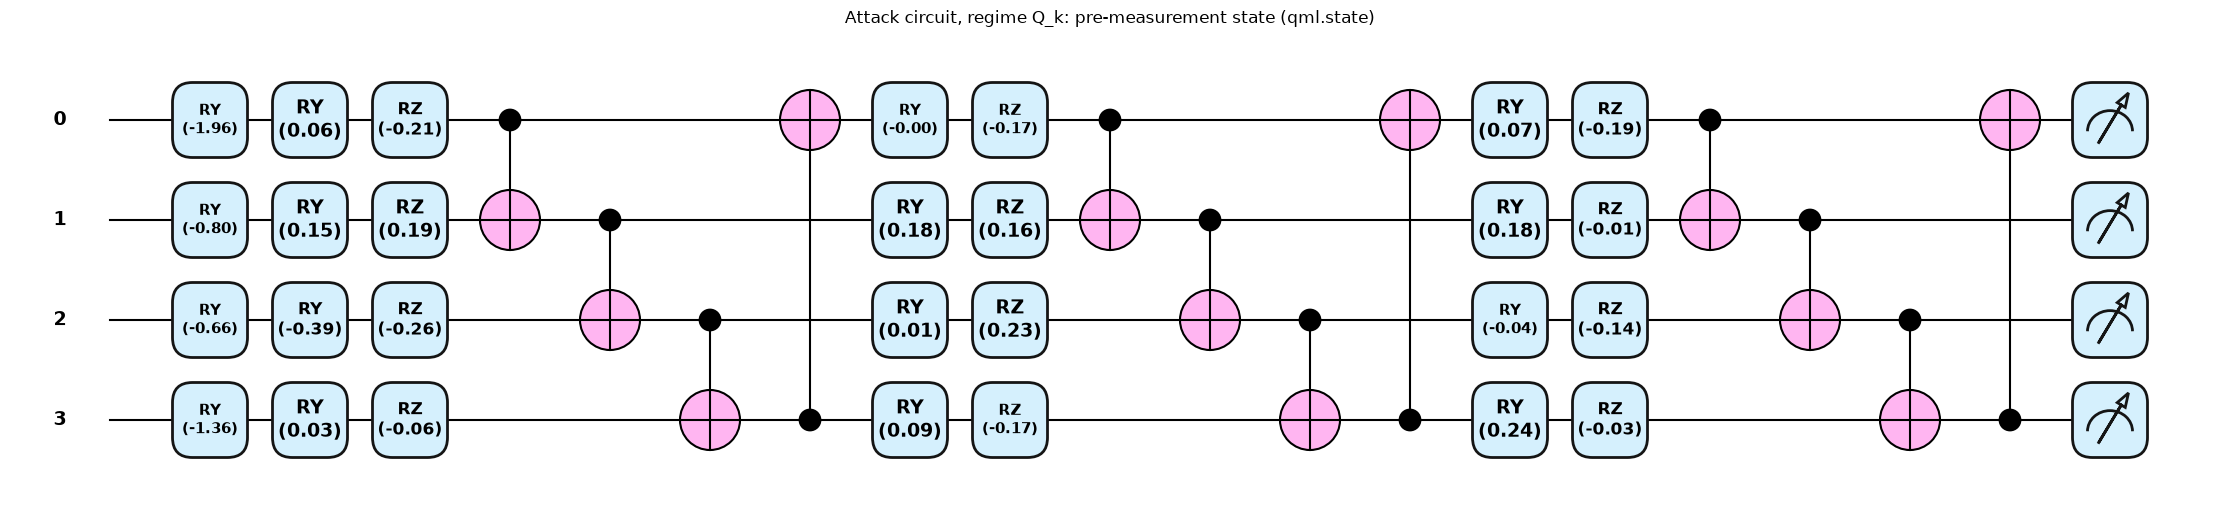

Attack circuit, regime Q_k: pre-measurement state (qml.state): qubits = 4, circuit depth = 19, trainable angles = 24  (RY + RZ on 4 qubits x 3 layers); encoding gates RY(pi x_i): 4; CNOTs: 12


In [8]:
dev = qml.device("default.qubit", wires=NQ)

def qnn(x, w):
    """Paper Fig. 1: RY(pi x_i) encoding, then 3 layers of [RY, RZ on every qubit; ring of CNOT]."""
    for q in range(NQ):
        qml.RY(np.pi * x[q], wires=q)
    for l in range(NL):
        for q in range(NQ):
            qml.RY(w[l, q, 0], wires=q)
            qml.RZ(w[l, q, 1], wires=q)
        for q in range(NQ):
            qml.CNOT(wires=[q, (q + 1) % NQ])

@qml.qnode(dev)
def victim_C(x, w):                 # regime C_k: fixed read-out ZIII
    qnn(x, w); return qml.expval(qml.PauliZ(0))

@qml.qnode(dev)
def attack_M(x, w):                 # regime M_k: attacker-chosen Pauli string, here X (x) Y (x) Z (x) X
    qnn(x, w); return qml.expval(qml.PauliX(0) @ qml.PauliY(1) @ qml.PauliZ(2) @ qml.PauliX(3))

@qml.qnode(dev)
def attack_Q(x, w):                 # regime Q_k: the pre-measurement state itself
    qnn(x, w); return qml.state()

rng_c = np.random.default_rng(SEED)
x_demo = TASK["0 vs 1"]["x_pop"][0]; w_demo = rng_c.normal(0, INIT_SCALE, (NL, NQ, 2))
for title, circ in [("Victim, regime C_k: read-out ZIII", victim_C), ("Attack circuit, regime M_k: Pauli string XYZX", attack_M), ("Attack circuit, regime Q_k: pre-measurement state (qml.state)", attack_Q)]:
    fig, ax = qml.draw_mpl(circ, decimals=2, style="pennylane")(x_demo, w_demo)
    fig.suptitle(title, y=1.02); plt.show()
    sp = qml.specs(circ)(x_demo, w_demo)
    res = sp.resources if hasattr(sp, "resources") else sp["resources"]
    depth = res.depth if hasattr(res, "depth") else res["depth"]
    print(f"{title}: qubits = {NQ}, circuit depth = {depth}, trainable angles = {w_demo.size}  (RY + RZ on {NQ} qubits x {NL} layers); encoding gates RY(pi x_i): {NQ}; CNOTs: {NL * NQ}")

In [9]:
# Equivalence of the fast simulator with the drawn PennyLane circuits: Pauli-string expectations (all 255 strings) and the full state vector.
import itertools
PAULI = {"I": np.eye(2), "X": np.array([[0, 1], [1, 0]]), "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1., -1.])}
STRINGS = ["".join(s) for s in itertools.product("IXYZ", repeat=NQ) if set(s) != {"I"}]          # 255 non-identity strings
WEIGHT  = np.array([sum(ch != "I" for ch in s) for s in STRINGS])
def pauli_matrix(s):
    m = np.array([[1.0 + 0j]])
    for ch in s: m = np.kron(m, PAULI[ch])
    return m
PM = np.stack([pauli_matrix(s) for s in STRINGS])                                              # (255, 16, 16)
IDX_ZIII = STRINGS.index("ZIII")
print("Pauli strings:", len(STRINGS), "| by weight 1..4:", [int((WEIGHT == w_).sum()) for w_ in range(1, 5)])

r_chk = np.random.default_rng(SEED + 1)
worst_state = worst_pauli = 0.0
for _ in range(5):
    x = r_chk.uniform(-1, 1, NQ); w = r_chk.normal(0, 1.0, (NL, NQ, 2))
    psi = model_unitaries(w[None])[0] @ encode(x)                                              # fast simulator
    worst_state = max(worst_state, np.abs(np.asarray(attack_Q(x, w)) - psi).max())
    for s_idx in r_chk.choice(len(STRINGS), 6, replace=False):                                 # random Pauli strings vs PennyLane observables
        s = STRINGS[s_idx]
        obs = None
        for q, ch in enumerate(s):
            if ch == "I": continue
            o = {"X": qml.PauliX, "Y": qml.PauliY, "Z": qml.PauliZ}[ch](q); obs = o if obs is None else obs @ o
        @qml.qnode(dev)
        def c_(x, w): qnn(x, w); return qml.expval(obs)
        worst_pauli = max(worst_pauli, abs(float(c_(x, w)) - np.real(np.conj(psi) @ PM[s_idx] @ psi)))
    worst_pauli = max(worst_pauli, abs(float(victim_C(x, w)) - np.sum(np.abs(psi) ** 2 * ZSIGN)), abs(float(attack_M(x, w)) - np.real(np.conj(psi) @ PM[STRINGS.index("XYZX")] @ psi)))
print(f"max |state difference| = {worst_state:.2e}; max |Pauli expectation difference| = {worst_pauli:.2e}")
assert worst_state < 1e-10 and worst_pauli < 1e-10, "the fast simulator does not reproduce the PennyLane circuit"
print("EQUIVALENCE OK: the batched simulator used for all experiments reproduces the drawn PennyLane circuits (states and Pauli expectations).")

Pauli strings: 255 | by weight 1..4: [12, 54, 108, 81]


max |state difference| = 2.80e-16; max |Pauli expectation difference| = 5.00e-16
EQUIVALENCE OK: the batched simulator used for all experiments reproduces the drawn PennyLane circuits (states and Pauli expectations).


## 3. Training the target and surrogate models in the paper's "two worlds"

The membership inference game needs models trained **with** and **without** the target point z. We build every ensemble from *pairs*: for pair *i* a random half S_i of the 512-point
population (256 points) trains one model and its complement trains the other. Hence every population point is a member of exactly one model of every pair: that is the
"in" model for z, the other is the "out" model for z, and K pairs give exactly K "in" and K "out" models for every z (**CHOICE**, a balanced version of Carlini et al.'s shadow models;
the paper only says that K pairs are trained).

Three independent ensembles are trained per task (different random halves, initialisations and mini-batch orders):

* **A** (attacker's surrogate models, `PAIRS_A` pairs): from these the attacker estimates the model-averaged outcome distributions / states; K <= `PAIRS_A` of them are used.
* **R** (reference, `PAIRS_R` pairs): an *independent* ensemble used as a proxy for the true model-averaged states, i.e. the "theoretical" optimum L that the paper compares with.
* **T** (fresh target models, `PAIRS_T` pairs): played by the challenger in Game 1, used for the out-of-sample advantage (the paper's plug-in estimate of Eq. 32 never tests on unseen models).

Training uses Adam (lr 0.05), 80 epochs, binary cross-entropy, init N(0, 0.2^2) and mini-batches of 32 (Fig. 1 training recipe of the paper; batch size is a **CHOICE**).

In [10]:
def train_ensemble(Phi_pop, y_pop, subsets, epochs, seed, tag=""):
    """Train M independent models in parallel (exact same maths as M separate trainings; Adam is element-wise).
    subsets (M, N_TRAIN): population indices of each model's training set. Returns U (M,16,16), final-epoch mean train loss (M,)."""
    M, n = subsets.shape
    r = np.random.default_rng(seed)
    theta = r.normal(0.0, INIT_SCALE, M * NL * NQ * 2)
    m1 = np.zeros_like(theta); m2 = np.zeros_like(theta); step = 0
    t0 = time.time()
    for ep in range(epochs):
        order = np.argsort(r.random((M, n)), axis=1)                      # an independent shuffle for every model
        idx = np.take_along_axis(subsets, order, 1)
        tot = 0.0
        for b in range(n // BATCH):
            ib = idx[:, b * BATCH:(b + 1) * BATCH]
            loss, g = _vg(theta, Phi_pop[ib], y_pop[ib]); tot += loss / M
            step += 1
            m1 = 0.9 * m1 + 0.1 * g; m2 = 0.999 * m2 + 0.001 * g * g       # Adam
            theta = theta - LR * (m1 / (1 - 0.9 ** step)) / (np.sqrt(m2 / (1 - 0.999 ** step)) + 1e-8)
        if ep == 0 or (ep + 1) % max(1, epochs // 4) == 0:
            print(f"   {tag} epoch {ep + 1:3d}/{epochs}  mean batch loss {tot / (n // BATCH):.4f}   ({time.time() - t0:.0f}s)", flush=True)
    return model_unitaries(theta.reshape(M, NL, NQ, 2))

def make_pairs(n_pairs, seed):
    """pair i: model 2i trained on S_i (random half), model 2i+1 on the complement.  Returns subsets (2*n_pairs, 256) and mem (n_pairs, N_POP) = [z in S_i]."""
    r = np.random.default_rng(seed)
    perms = np.stack([r.permutation(N_POP) for _ in range(n_pairs)])
    S, C = perms[:, :N_TRAIN], perms[:, N_TRAIN:]
    subsets = np.stack([S, C], 1).reshape(2 * n_pairs, N_TRAIN)
    mem = np.zeros((n_pairs, N_POP), bool); np.put_along_axis(mem, S, True, 1)
    return subsets, mem

def states_of(U, X):
    """Pre-measurement states psi_theta(x) = U |phi(x)> for models U (M,16,16) and inputs X (n,4): (M, n, 16) complex."""
    return np.einsum('mij,nj->mni', U, encode(X))

ENS = {nm: {} for nm in TASK}
t_train = time.time()
for ti, (nm, T) in enumerate(TASK.items()):
    print(f"=== task '{nm}' ===")
    Phi_pop = encode(T["x_pop"])
    for ename, npairs, es in [("A", PAIRS_A, 1), ("R", PAIRS_R, 2), ("T", PAIRS_T, 3)]:
        sub, mem = make_pairs(npairs, SEED + 1000 * (ti + 1) + es)
        U = train_ensemble(Phi_pop, T["y_pop"], sub, EPOCHS, SEED + 1000 * (ti + 1) + 10 * es, tag=f"[{nm} / {ename}: {2 * npairs} models]")
        ENS[nm][ename] = dict(U=U, sub=sub, mem=mem, Psi=states_of(U, T["x_pop"]).reshape(npairs, 2, N_POP, DIM))
print(f"training done in {(time.time() - t_train) / 60:.1f} min")

=== task '0 vs 1' ===


   [0 vs 1 / A: 256 models] epoch   1/80  mean batch loss 0.5820   (1s)


   [0 vs 1 / A: 256 models] epoch  20/80  mean batch loss 0.0720   (25s)


   [0 vs 1 / A: 256 models] epoch  40/80  mean batch loss 0.0662   (59s)


   [0 vs 1 / A: 256 models] epoch  60/80  mean batch loss 0.0651   (94s)


...

   [3 vs 8 / T: 128 models] epoch  20/80  mean batch loss 0.3625   (17s)


   [3 vs 8 / T: 128 models] epoch  40/80  mean batch loss 0.3581   (32s)


   [3 vs 8 / T: 128 models] epoch  60/80  mean batch loss 0.3561   (45s)


   [3 vs 8 / T: 128 models] epoch  80/80  mean batch loss 0.3558   (59s)


training done in 9.8 min


In [11]:
# How good are the models?  accuracy on their own training points, on the other half of the population, and on 1000 unseen MNIST test images.
rows = []
for nm, T in TASK.items():
    for ename in ("A", "R", "T"):
        E = ENS[nm][ename]; P = E["Psi"].shape[0]
        f_pop = np.einsum('pszi,i->psz', np.abs(E["Psi"]) ** 2, ZSIGN)                  # <Z0> for every model and population point
        pred = (f_pop < 0).astype(float)                                              # p(class 1) = (1 - f)/2 > 1/2
        inmask = np.stack([E["mem"], ~E["mem"]], 1)                                    # (P, 2, N_POP): z in the model's training set
        corr = pred == T["y_pop"][None, None, :]
        acc_tr = corr[inmask].mean(); acc_out = corr[~inmask].mean()
        fe = np.einsum('mni,i->mn', np.abs(states_of(E["U"][:min(len(E["U"]), 64)], T["x_ev"])) ** 2, ZSIGN)
        acc_te = ((fe < 0).astype(float) == T["y_ev"][None, :]).mean()
        rows.append(dict(task=nm, ensemble=ename, models=2 * P, train_acc=acc_tr, other_half_acc=acc_out, test_acc=acc_te, gap_train_minus_other=acc_tr - acc_out))
MODEL_QUALITY = pd.DataFrame(rows).set_index(["task", "ensemble"])
display(MODEL_QUALITY.round(4))

models  train_acc  other_half_acc  test_acc  gap_train_minus_other
task   ensemble                                                                    
0 vs 1 A            256     0.9904          0.9894    0.9944                 0.0010
       R            256     0.9908          0.9899    0.9945                 0.0009
       T            128     0.9917          0.9906    0.9943                 0.0011
3 vs 8 A            256     0.8515          0.8411    0.8578                 0.0104
       R            256     0.8504          0.8427    0.8558                 0.0077
       T            128     0.8517          0.8412    0.8578                 0.0105

## 4. The three attackers, computed exactly

For a target z the challenger's two worlds produce, for every model, a pure state `psi = U |phi(x_z)>`. The attacker's K surrogate pairs give K "in" states (models trained with z) and
K "out" states (models trained without z). With k shots/copies the model-averaged k-copy states are

`Omega_b = (1/K) sum_i |psi_i><psi_i|^(tensor k)`, b = 1 ("in") or 0 ("out"),

and the plug-in advantage of Eq. 32 is the total variation or trace distance between the two averages. All three regimes are computed **exactly** (no sampling noise from the shots):

* **C_k.** One shot of `ZIII` gives 1 with probability p_i = (1 - <Z0>_i)/2. For i.i.d. shots the count n is a sufficient statistic and is binomial(k, p_i); the "in" and "out" count distributions are the K-averages of those binomials and the optimal test is the likelihood-ratio test, whose advantage is their total variation distance (Eq. 16).
* **M_k.** Same, but for each of the 255 Pauli strings P the outcome of a shot is the eigenvalue +1 or -1 of P, with probability (1 + <P>_i)/2. The attacker picks the best string for each z (the "supremum" of the paper); for Fig. 3 the maximum is restricted to strings of Pauli weight <= 1, 2, 3, 4.
* **Q_k.** The Helstrom measurement distinguishes `Omega_1` from `Omega_0` with advantage `L_Q = 1/2 || Omega_1 - Omega_0 ||_1` (Eq. 25). Writing `Omega_1 - Omega_0 = A D A^dagger` with `A = [ |psi_1>^k, ..., |psi_2K>^k ]` and `D = diag(+1/K, ..., -1/K)`, its non-zero eigenvalues are those of `D G` where `G_ij = <psi_i|psi_j>^k` is the 2K x 2K Gram matrix, so we never build the 16^k-dimensional matrices.
  The same algebra gives the probability that the Helstrom measurement of a *fresh* model's k-copy state says "member", which we use for the out-of-sample advantage.

Two kinds of advantage are reported (see "Reading the paper critically" for why):
**in-sample** = distance between the attacker's own K-averages (the paper's Eq. 32 plug-in estimate), and **out-of-sample** = the attacker's decision rule (built from the K surrogate pairs) applied to
the models of the independent ensemble T, which the attacker has never seen: advantage = P(says member | in) - P(says member | out), the quantity Game 1 actually defines.

In [12]:
# ---------- building blocks ----------
PFLAT = PM.transpose(2, 1, 0).reshape(DIM * DIM, len(STRINGS))                # PFLAT[a*16+b, s] = P_s[b, a]  so  <P> = Re sum_ab rho_ab P_ba
PFR, PFI = np.ascontiguousarray(PFLAT.real), np.ascontiguousarray(PFLAT.imag)
_LOGC = {}
def _logc(k):
    if k not in _LOGC:
        n = np.arange(k + 1); _LOGC[k] = scipy.special.gammaln(k + 1) - scipy.special.gammaln(n + 1) - scipy.special.gammaln(k - n + 1)
    return _LOGC[k]

def pauli_expect(psi):
    """psi (..., 16) complex -> <psi|P|psi> for all 255 strings, shape (..., 255)."""
    sh = psi.shape[:-1]; p = psi.reshape(-1, DIM)
    rho = (p[:, :, None] * np.conj(p)[:, None, :]).reshape(-1, DIM * DIM)
    return (rho.real @ PFR - rho.imag @ PFI).reshape(*sh, len(STRINGS))

def binom_pmf(p, k):
    """Binomial(k, p) pmf over n = 0..k, vectorised over p (any shape); output shape p.shape + (k+1,)."""
    p = np.clip(p, 1e-12, 1 - 1e-12); n = np.arange(k + 1)
    return np.exp(_logc(k) + n * np.log(p)[..., None] + (k - n) * np.log1p(-p)[..., None])

def select(ens, zs):
    """For the target points zs: the K 'in' states (trained with z) and K 'out' states (trained without z), each (P, len(zs), 16)."""
    Psi, mem = ens["Psi"], ens["mem"]; P = Psi.shape[0]
    side_in = (~mem[:, zs]).astype(int)                          # model 0 of the pair was trained on S_i: it is the 'in' model iff z in S_i
    ar = np.arange(P)[:, None]
    return Psi[ar, side_in, zs[None, :]], Psi[ar, 1 - side_in, zs[None, :]]

def helstrom(Vin, Vout, k, Vtest=None):
    """Exact Helstrom analysis of  Omega_in - Omega_out  for k copies, from the Gram matrix of the 2K pure states.
    Vin, Vout (Z, K, 16).  Returns L = 1/2 ||Omega_in - Omega_out||_1  (Z,), and with Vtest (Z, T, 16) also the probability (Z, T) that the
    Helstrom measurement (projector on the positive part of the difference) says 'member' on |t>^(tensor k); the part of |t>^k outside the span is a coin flip."""
    Z, K, _ = Vin.shape
    V = np.concatenate([Vin, Vout], 1)
    G = np.einsum('zia,zja->zij', V.conj(), V) ** k                                # <v_i|v_j>^k
    S, W = np.linalg.eigh(G)
    keep = S > 1e-10 * S[:, -1:]
    sq  = np.where(keep, np.sqrt(np.clip(S, 0, None)), 0.0)
    isq = np.where(keep, 1.0 / np.sqrt(np.clip(S, 1e-300, None)), 0.0)
    d = np.concatenate([np.ones(K), -np.ones(K)]) / K                            # +1/K: members ("in"), -1/K: non-members ("out")
    H = sq[:, :, None] * np.einsum('zia,i,zib->zab', W.conj(), d, W) * sq[:, None, :]
    lam, Qv = np.linalg.eigh(H)
    L = 0.5 * np.abs(lam).sum(-1)
    if Vtest is None:
        return L
    g = np.einsum('zia,zta->zit', V.conj(), Vtest) ** k                           # <v_j|t>^k
    u = isq[:, :, None] * np.einsum('zia,zit->zat', W.conj(), g)
    w2 = np.abs(np.einsum('zab,zat->zbt', Qv.conj(), u)) ** 2
    p_pos = (w2 * (lam > 1e-12)[:, :, None]).sum(1); p_neg = (w2 * (lam < -1e-12)[:, :, None]).sum(1)
    return L, p_pos + 0.5 * np.clip(1 - p_pos - p_neg, 0, 1)

def attack_scan(ens, jobs, zs, test=None, K_test=None, tag=""):
    """In-sample advantages of the three regimes for the target points zs.
    jobs: {k: [K, ...]}.  Returns res[(k, K)] = {'C','M1','M2','M3','M4','Q'} -> arrays over zs.
    If `test` (ensemble T) is given, also the out-of-sample advantages at K = K_test: held[k] = {'C','M','Q'} -> arrays over zs."""
    nz = len(zs); res, held = {}, {}
    for k, Ks in jobs.items():
        for K in Ks: res[(k, K)] = {key: np.zeros(nz) for key in ("C", "M1", "M2", "M3", "M4", "Q")}
        if test is not None and K_test in Ks: held[k] = {key: np.zeros(nz) for key in ("C", "M", "Q")}
    ZC = 16; t0 = time.time()
    for z0 in range(0, nz, ZC):
        zc = zs[z0:z0 + ZC]; nzc = len(zc)
        pin, pout = select(ens, zc); Ein, Eout = pauli_expect(pin), pauli_expect(pout)           # (P, nzc, 255)
        if test is not None:
            tin, tout = select(test, zc); Tin, Tout = pauli_expect(tin), pauli_expect(tout)
            PT = tin.shape[0]
        for k, Ks in jobs.items():
            Kk = max(Ks); sub = max(1, int(3e6 // (Kk * len(STRINGS) * (k + 1))))
            # ---- classical-outcome regimes C_k and M_k
            for a in range(0, nzc, sub):
                sl = slice(a, min(nzc, a + sub)); s_ = sl.stop - sl.start
                pm_in = binom_pmf((1 + Ein[:Kk, sl]) / 2, k); pm_out = binom_pmf((1 + Eout[:Kk, sl]) / 2, k)    # (Kk, s, 255, k+1)
                np.cumsum(pm_in, axis=0, out=pm_in); np.cumsum(pm_out, axis=0, out=pm_out)
                for K in Ks:
                    mi, mo = pm_in[K - 1] / K, pm_out[K - 1] / K                                 # model-averaged outcome distributions (s, 255, k+1)
                    tv = 0.5 * np.abs(mi - mo).sum(-1)                                           # (s, 255): plug-in advantage for every Pauli string
                    r = res[(k, K)]; dst = slice(z0 + sl.start, z0 + sl.stop)
                    r["C"][dst] = tv[:, IDX_ZIII]
                    for w_ in (1, 2, 3, 4): r[f"M{w_}"][dst] = tv[:, WEIGHT <= w_].max(1)
                    if k in held and K == K_test:                                                # out-of-sample: likelihood-ratio rule on fresh models
                        ar = np.arange(s_)
                        for name, sidx in (("C", np.full(s_, IDX_ZIII)), ("M", tv.argmax(1))):
                            di, do = mi[ar, sidx], mo[ar, sidx]; dec = (di > do) + 0.5 * (di == do)          # P(say 'member' | count n)
                            p1 = (binom_pmf((1 + Tin[:, sl][:, ar, sidx]) / 2, k) * dec[None]).sum(-1)       # (PT, s)
                            p0 = (binom_pmf((1 + Tout[:, sl][:, ar, sidx]) / 2, k) * dec[None]).sum(-1)
                            held[k][name][dst] = p1.mean(0) - p0.mean(0)
                del pm_in, pm_out
            # ---- quantum-state regime Q_k
            for K in Ks:
                Zq = max(1, int(1.5e6 // (2 * K) ** 2))
                for a in range(0, nzc, Zq):
                    sl = slice(a, min(nzc, a + Zq)); dst = slice(z0 + sl.start, z0 + sl.stop)
                    Vin, Vout = pin[:K, sl].transpose(1, 0, 2), pout[:K, sl].transpose(1, 0, 2)
                    if k in held and K == K_test:
                        Vt = np.concatenate([tin[:, sl], tout[:, sl]], 0).transpose(1, 0, 2)
                        L, P1 = helstrom(Vin, Vout, k, Vt)
                        held[k]["Q"][dst] = P1[:, :PT].mean(1) - P1[:, PT:].mean(1)
                    else:
                        L = helstrom(Vin, Vout, k)
                    res[(k, K)]["Q"][dst] = L
        print(f"   {tag} targets {z0 + nzc}/{nz} done ({time.time() - t0:.0f}s)", flush=True)
    return res, held

In [13]:
# ---------- checks of the exact computations against brute force ----------
def explicit_omega(V, k):
    out = 0
    for v in V:
        st = np.array([1.0 + 0j])
        for _ in range(k): st = np.kron(st, v)
        out = out + np.outer(st, st.conj())
    return out / len(V)

nm0 = list(TASK)[0]; EA = ENS[nm0]["A"]; zs_chk = np.array([0, 1, 2])
pin, pout = select(EA, zs_chk); K_chk = 6
rows = []
for k in (1, 2):
    L_gram = helstrom(pin[:K_chk].transpose(1, 0, 2), pout[:K_chk].transpose(1, 0, 2), k)
    L_explicit = np.array([0.5 * np.abs(np.linalg.eigvalsh(explicit_omega(pin[:K_chk, j], k) - explicit_omega(pout[:K_chk, j], k))).sum() for j in range(len(zs_chk))])
    # Theorem III.1: classical outcomes (ZIII): the diagonal states give a trace distance equal to the total variation distance of the count distributions
    p_in, p_out = (1 - np.einsum('pzi,i->pz', np.abs(pin[:K_chk]) ** 2, ZSIGN)) / 2, (1 - np.einsum('pzi,i->pz', np.abs(pout[:K_chk]) ** 2, ZSIGN)) / 2
    def seq_dist(p):                       # distribution over the 2^k outcome sequences, averaged over the K models
        return np.mean([[np.prod([(pi if b else 1 - pi) for b in bits]) for bits in itertools.product([0, 1], repeat=k)] for pi in p], axis=0)
    tv_seq = np.array([0.5 * np.abs(seq_dist(p_in[:, j]) - seq_dist(p_out[:, j])).sum() for j in range(len(zs_chk))])
    tv_cnt = np.array([0.5 * np.abs(binom_pmf(p_in[:, j], k).mean(0) - binom_pmf(p_out[:, j], k).mean(0)).sum() for j in range(len(zs_chk))])
    rows.append(dict(k=k, L_Q_gram=L_gram.round(6).tolist(), L_Q_explicit_16k_dim=L_explicit.round(6).tolist(),
                     TV_sequences=tv_seq.round(6).tolist(), TV_counts=tv_cnt.round(6).tolist()))
    assert np.allclose(L_gram, L_explicit, atol=1e-8), "Gram-matrix Helstrom != explicit trace norm"
    assert np.allclose(tv_seq, tv_cnt, atol=1e-8), "count sufficient statistic != full sequence distribution"
display(pd.DataFrame(rows).set_index("k"))
print("CHECK OK: the Gram-matrix Helstrom advantage equals the explicit trace distance of the 16^k-dimensional k-copy states, and the binomial-count total variation equals the total variation of the full outcome sequences (Theorem III.1 for diagonal states).")

,L_Q_gram,L_Q_explicit_16k_dim,TV_sequences,TV_counts
k,,,,
1,"[0.553383, 0.601089, 0.528616]","[0.553383, 0.601089, 0.528616]","[0.005306, 0.004361, 0.001985]","[0.005306, 0.004361, 0.001985]"
2,"[0.843569, 0.849679, 0.735295]","[0.843569, 0.849679, 0.735295]","[0.010299, 0.008561, 0.00395]","[0.010299, 0.008561, 0.00395]"


CHECK OK: the Gram-matrix Helstrom advantage equals the explicit trace distance of the 16^k-dimensional k-copy states, and the binomial-count total variation equals the total variation of the full outcome sequences (Theorem III.1 for diagonal states).


### Running the attacks

For every task, ensemble A is scanned for all (K, k) pairs of the paper (Figs. 2 and 3: K up to `K_MAIN`, all six shot numbers; Fig. 4: K up to 128 for k = 2, 4, 8), the independent ensemble R is scanned once at K = K_REF
(the "theoretical" proxy) and, at K = `K_MAIN`, the decision rules are also evaluated out-of-sample on the fresh target ensemble T.

In [14]:
JOBS_A = {k: [K for K in K_LIST if K <= K_MAIN] for k in SHOT_LIST}
for k in GAP_SHOTS: JOBS_A[k] = sorted(set(JOBS_A.get(k, [])) | set(K_LIST))
JOBS_R = {k: [K_REF] for k in GAP_SHOTS}
r_z = np.random.default_rng(SEED + 7)
ZS = np.sort(r_z.choice(N_POP, N_Z, replace=False)) if N_Z < N_POP else np.arange(N_POP)          # target points z evaluated

RES, HELD, REFS = {}, {}, {}
t_att = time.time()
for nm in TASK:
    print(f"=== attacks on task '{nm}' ===")
    RES[nm], HELD[nm] = attack_scan(ENS[nm]["A"], JOBS_A, ZS, test=ENS[nm]["T"], K_test=K_MAIN, tag=f"[{nm} / A]")
    REFS[nm], _ = attack_scan(ENS[nm]["R"], JOBS_R, ZS, tag=f"[{nm} / R]")
print(f"attacks done in {(time.time() - t_att) / 60:.1f} min")

=== attacks on task '0 vs 1' ===


   [0 vs 1 / A] targets 16/128 done (55s)


   [0 vs 1 / A] targets 32/128 done (124s)


   [0 vs 1 / A] targets 48/128 done (212s)


   [0 vs 1 / A] targets 64/128 done (314s)


...

   [3 vs 8 / R] targets 80/128 done (197s)


   [3 vs 8 / R] targets 96/128 done (230s)


   [3 vs 8 / R] targets 112/128 done (277s)


   [3 vs 8 / R] targets 128/128 done (323s)


attacks done in 34.7 min


## 5. Results: the paper's Figs. 2, 3 and 4 redrawn

**Fig. 2** (membership inference advantage L versus the number of shots k at K = `K_MAIN` surrogate pairs, and versus the number of surrogate pairs K at k = 32), averaged over all evaluated target points z.
Solid lines are the in-sample plug-in estimate of the paper's Eq. 32; dashed lines (with markers) are the out-of-sample advantage on fresh models, which the paper does not report.
Error bars are standard errors over the target points.

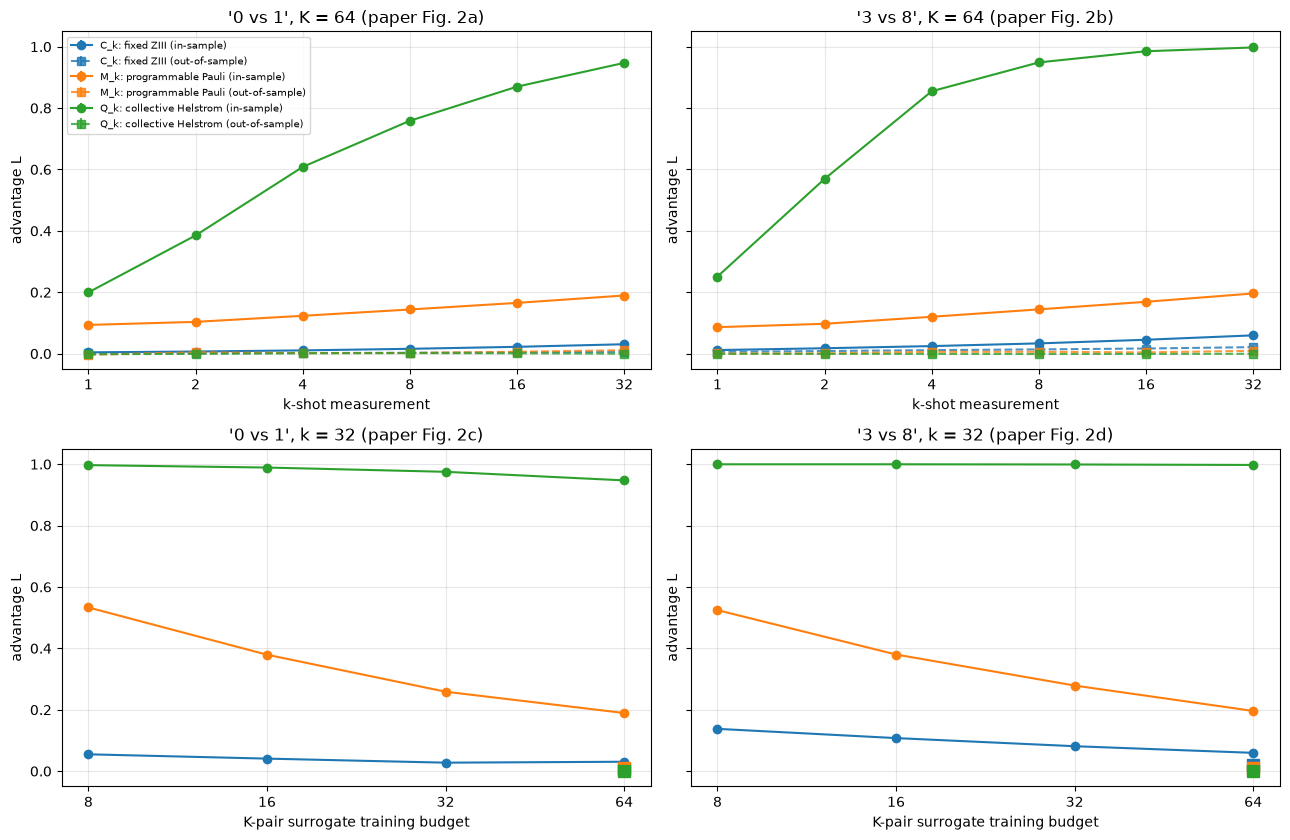

Mean advantage over the 128 target points at K = 64 surrogate pairs (in-sample = paper's plug-in estimate; out-of-sample = on 128 fresh target models):


C in-sample  M in-sample  Q in-sample  C out-of-sample  M out-of-sample  Q out-of-sample
task   k                                                                                           
0 vs 1 1         0.004        0.094        0.200            0.001           -0.003           -0.002
       2         0.007        0.104        0.385            0.001            0.004           -0.001
       4         0.011        0.123        0.608            0.002            0.002            0.001
       8         0.016        0.144        0.759            0.003            0.002            0.002
       16        0.022        0.165        0.870            0.004            0.006            0.001
       32        0.031        0.189        0.947            0.006            0.011           -0.000
3 vs 8 1         0.012        0.086        0.251            0.006            0.001           -0.001
       2         0.018        0.097        0.569            0.008            0.001           -0.001
       4         0.025        0.120        0.855            0.011            0.006           -0.001
       8         0.033        0.144        0.949            0.014            0.006           -0.001
       16        0.045        0.169        0.985            0.017            0.004           -0.001
       32        0.060        0.196        0.997            0.021            0.009           -0.000

In [15]:
COL = {"C": "tab:blue", "M": "tab:orange", "Q": "tab:green"}
LAB = {"C": "C_k: fixed ZIII", "M": "M_k: programmable Pauli", "Q": "Q_k: collective Helstrom"}
def mean_sem(a): a = np.asarray(a); return a.mean(), a.std(ddof=1) / np.sqrt(len(a)) if len(a) > 1 else 0.0
def Lcurve(nm, reg, ks=None, Ks=None):
    key = "M4" if reg == "M" else reg
    if ks is not None: return [mean_sem(RES[nm][(k, K_MAIN)][key]) for k in ks]
    return [mean_sem(RES[nm][(32 if 32 in SHOT_LIST else max(SHOT_LIST), K)][key]) for K in Ks]

K_SWEEP = [K for K in K_LIST if K <= K_MAIN]; K_FIX = 32 if 32 in SHOT_LIST else max(SHOT_LIST)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharey=True)
for j, nm in enumerate(TASK):
    ax = axes[0, j]
    for reg in "CMQ":
        m, s = np.array(Lcurve(nm, reg, ks=SHOT_LIST)).T
        ax.errorbar(SHOT_LIST, m, s, color=COL[reg], marker="o", label=LAB[reg] + " (in-sample)")
        if reg in HELD[nm][SHOT_LIST[0]]:
            mh, sh = np.array([mean_sem(HELD[nm][k][reg]) for k in SHOT_LIST]).T
            ax.errorbar(SHOT_LIST, mh, sh, color=COL[reg], marker="s", ls="--", alpha=0.8, label=LAB[reg] + " (out-of-sample)")
    ax.set_xscale("log", base=2); ax.set_xticks(SHOT_LIST); ax.set_xticklabels(SHOT_LIST)
    ax.set_xlabel("k-shot measurement"); ax.set_ylabel("advantage L"); ax.set_title(f"'{nm}', K = {K_MAIN} (paper Fig. 2{'ab'[j]})"); ax.set_ylim(-0.05, 1.05)
    if j == 0: ax.legend(fontsize=7.5, loc="upper left")
    ax = axes[1, j]
    for reg in "CMQ":
        m, s = np.array(Lcurve(nm, reg, Ks=K_SWEEP)).T
        ax.errorbar(K_SWEEP, m, s, color=COL[reg], marker="o", label=LAB[reg])
        if K_FIX in HELD[nm] and reg in HELD[nm][K_FIX]:
            mh, sh = mean_sem(HELD[nm][K_FIX][reg]); ax.errorbar([K_MAIN], [mh], [sh], color=COL[reg], marker="s", ls="", markersize=8, label=LAB[reg] + " (out-of-sample, K=%d)" % K_MAIN if reg == "C" else None)
    ax.set_xscale("log", base=2); ax.set_xticks(K_SWEEP); ax.set_xticklabels(K_SWEEP)
    ax.set_xlabel("K-pair surrogate training budget"); ax.set_ylabel("advantage L"); ax.set_title(f"'{nm}', k = {K_FIX} (paper Fig. 2{'cd'[j]})"); ax.set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.show()

rows = []
for nm in TASK:
    for k in SHOT_LIST:
        r = {"task": nm, "k": k}
        for reg in "CMQ":
            r[f"{reg} in-sample"] = RES[nm][(k, K_MAIN)]["M4" if reg == "M" else reg].mean()
        for reg in "CMQ":
            r[f"{reg} out-of-sample"] = HELD[nm][k][reg].mean()
        rows.append(r)
SUMMARY = pd.DataFrame(rows).set_index(["task", "k"])
print(f"Mean advantage over the {len(ZS)} target points at K = {K_MAIN} surrogate pairs (in-sample = paper's plug-in estimate; out-of-sample = on {PAIRS_T * 2} fresh target models):")
display(SUMMARY.round(3))

**Fig. 3**: advantage under M_k when the attacker may only use Pauli strings of weight <= 1, 2, 3, 4 (number of non-identity factors), with C_k and Q_k as the lower and upper reference, at K = `K_MAIN`.

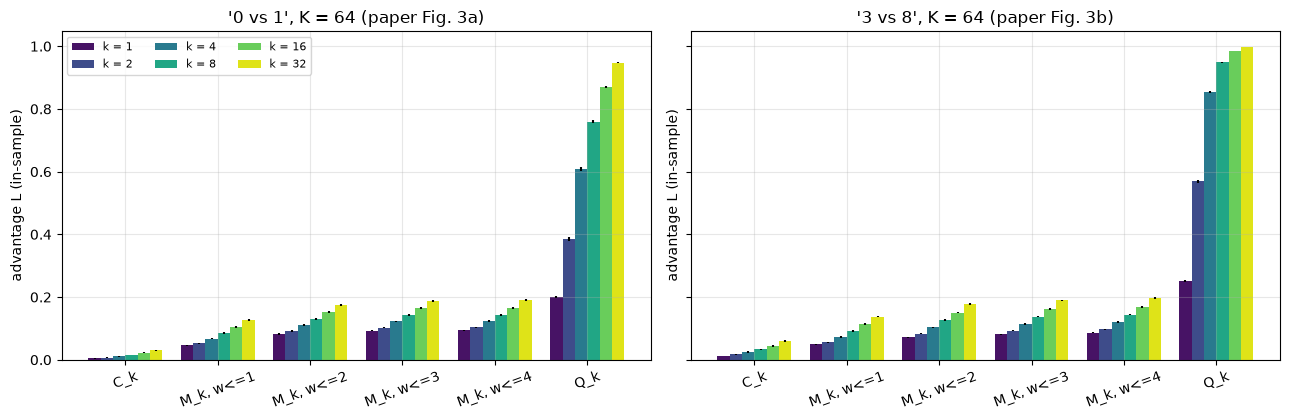

In [16]:
fams = [("C", "C_k"), ("M1", "M_k, w<=1"), ("M2", "M_k, w<=2"), ("M3", "M_k, w<=3"), ("M4", "M_k, w<=4"), ("Q", "Q_k")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
cmap = plt.cm.viridis(np.linspace(0.05, 0.95, len(SHOT_LIST)))
for ax, nm in zip(axes, TASK):
    wbar = 0.8 / len(SHOT_LIST)
    for ik, k in enumerate(SHOT_LIST):
        m = [RES[nm][(k, K_MAIN)][key].mean() for key, _ in fams]; s = [mean_sem(RES[nm][(k, K_MAIN)][key])[1] for key, _ in fams]
        ax.bar(np.arange(len(fams)) + (ik - len(SHOT_LIST) / 2 + 0.5) * wbar, m, wbar, yerr=s, color=cmap[ik], label=f"k = {k}")
    ax.set_xticks(range(len(fams))); ax.set_xticklabels([f[1] for f in fams], rotation=20); ax.set_ylabel("advantage L (in-sample)")
    ax.set_title(f"'{nm}', K = {K_MAIN} (paper Fig. 3{'ab'[list(TASK).index(nm)]})")
axes[0].legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

**Fig. 4**: the gap between the "theoretical" advantage L (proxy: the same estimator on the independent reference ensemble R with K_REF pairs) and the empirical advantage from K surrogate pairs,
`eps = |L_ref - L_hat(K)|`, averaged over targets, for k = 2, 4, 8 and the three regimes. The dotted line is K^(-1/2). Note that with a proxy built from the same estimator and a finite K_REF, the gap cannot
shrink below the sampling noise of the proxy itself.

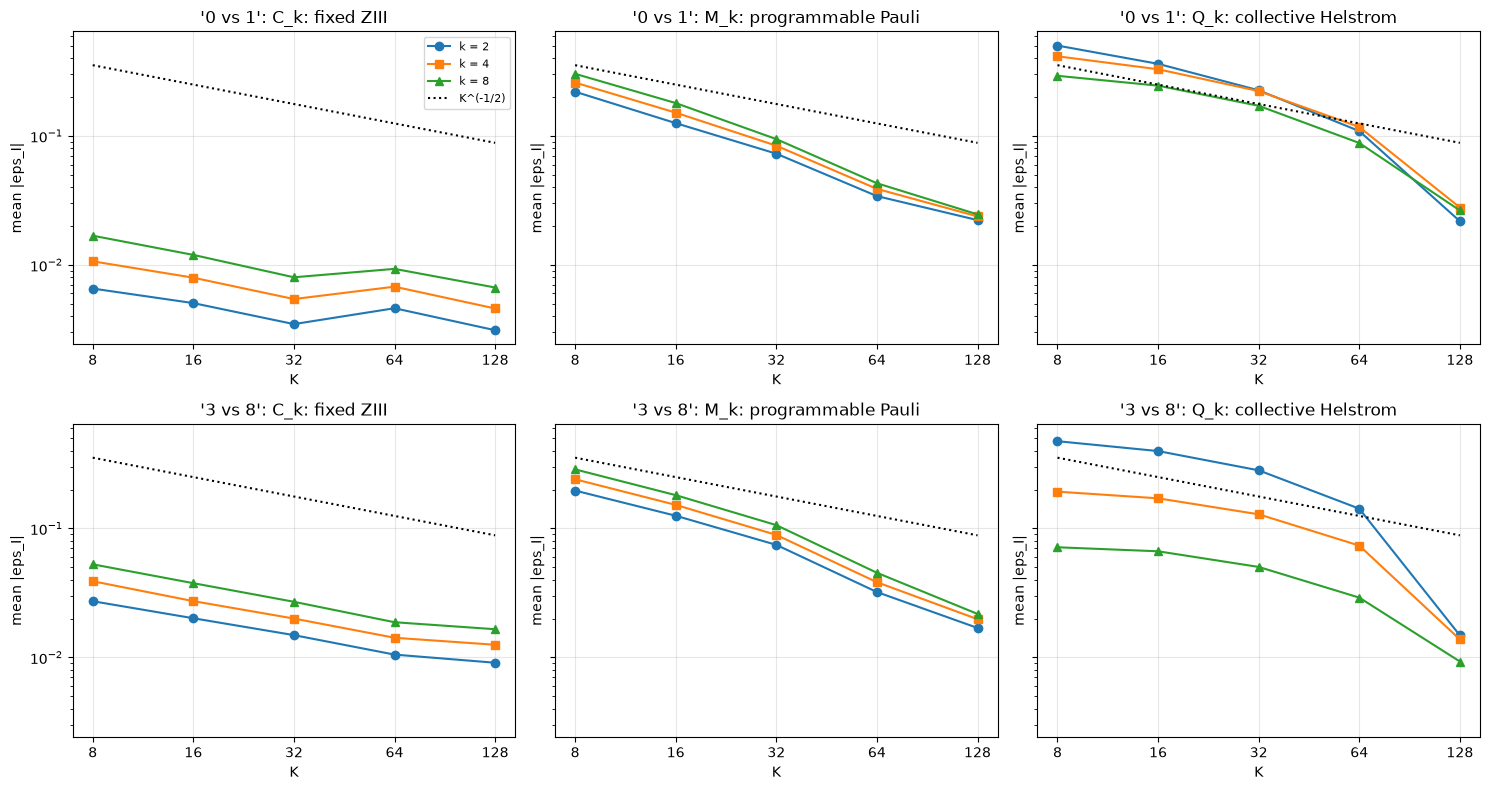

eps(K=8)  eps(K=16)  eps(K=32)  eps(K=64)  eps(K=128)  loglog_slope  bound_sqrt_2d_k_over_K_at_Kmax
task   regime k                                                                                                     
0 vs 1 C      2    0.0066     0.0051     0.0035     0.0046      0.0031       -0.2278                             2.0
              4    0.0107     0.0080     0.0054     0.0068      0.0046       -0.2661                            32.0
              8    0.0168     0.0120     0.0080     0.0093      0.0067       -0.3030                          8192.0
       M      2    0.2202     0.1256     0.0728     0.0342      0.0222       -0.8494                             2.0
              4    0.2592     0.1515     0.0840     0.0389      0.0238       -0.8857                            32.0
              8    0.3031     0.1798     0.0945     0.0430      0.0246       -0.9308                          8192.0
       Q      2    0.5019     0.3622     0.2258     0.1090      0.0218       -1.0781                             2.0
              4    0.4144     0.3288     0.2227     0.1173      0.0279       -0.9278                            32.0
              8    0.2924     0.2453     0.1713     0.0881      0.0264       -0.8413                          8192.0
3 vs 8 C      2    0.0273     0.0201     0.0149     0.0105      0.0091       -0.4106                             2.0
              4    0.0390     0.0273     0.0200     0.0142      0.0125       -0.4217                            32.0
              8    0.0527     0.0376     0.0270     0.0187      0.0165       -0.4350                          8192.0
       M      2    0.1965     0.1254     0.0745     0.0321      0.0169       -0.9043                             2.0
              4    0.2406     0.1523     0.0891     0.0383      0.0198       -0.9200                            32.0
              8    0.2869     0.1812     0.1061     0.0453      0.0217       -0.9445                          8192.0
       Q      2    0.4746     0.3979     0.2822     0.1422      0.0148       -1.1488                             2.0
              4    0.1928     0.1711     0.1287     0.0736      0.0138       -0.8831                            32.0
              8    0.0714     0.0665     0.0503     0.0291      0.0093       -0.7079                          8192.0

In [17]:
GAP = {}
for nm in TASK:
    for reg in "CMQ":
        key = "M4" if reg == "M" else reg
        for k in GAP_SHOTS:
            ref = REFS[nm][(k, K_REF)][key]
            GAP[(nm, reg, k)] = np.array([np.mean(np.abs(ref - RES[nm][(k, K)][key])) for K in K_LIST])

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
mk = {2: "o", 4: "s", 8: "^"}
for i, nm in enumerate(TASK):
    for j, reg in enumerate("CMQ"):
        ax = axes[i, j]
        for k in GAP_SHOTS:
            ax.plot(K_LIST, np.maximum(GAP[(nm, reg, k)], 1e-9), marker=mk.get(k, "o"), label=f"k = {k}")
        ax.plot(K_LIST, np.array(K_LIST, float) ** -0.5, "k:", label="K^(-1/2)")
        ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xticks(K_LIST); ax.set_xticklabels(K_LIST)
        ax.set_xlabel("K"); ax.set_ylabel("mean |eps_I|"); ax.set_title(f"'{nm}': {LAB[reg]}")
        if i == 0 and j == 0: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for (nm, reg, k), g in GAP.items():
    x = np.log(np.array(K_LIST, float)); y = np.log(np.maximum(g, 1e-12))
    rows.append(dict(task=nm, regime=reg, k=k, **{f"eps(K={K})": v for K, v in zip(K_LIST, g)}, loglog_slope=np.polyfit(x, y, 1)[0],
                     bound_sqrt_2d_k_over_K_at_Kmax=float(np.sqrt(2 * DIM ** k / K_LIST[-1]))))
GAPTAB = pd.DataFrame(rows).set_index(["task", "regime", "k"])
display(GAPTAB.round(4))

## 6. Beyond the paper: a classical-adversary baseline on the same inputs

The paper's attackers are all *optimal likelihood-ratio* tests that know the per-target outcome distributions. As a classical reference we run the standard population-level
**confidence-threshold attack** (Yeom et al. 2018, the base of Shokri/Su et al.) on the same data splits: the attacker sees the model's confidence in the true label of z, and a single threshold
(chosen on the attacker's surrogate pairs to maximise TPR - FPR) decides membership of z in *fresh* models. It is applied to the QNN (using <Z0>, i.e. the k -> infinity limit of regime C) and to three classical models trained on the
**identical 4 angle features and identical training halves**: logistic regression, a random forest (100 trees) and an RBF-kernel SVM.

In [18]:
from sklearn.metrics import roc_curve
def conf_in_out(conf, mem):
    """conf (P, 2, n_z): confidence in the true label for model side 0 (trained on S_i) / side 1; returns (P, n_z) for the 'in' and 'out' model."""
    P = conf.shape[0]; side_in = (~mem).astype(int); ar = np.arange(P)[:, None]; zi = np.arange(conf.shape[2])[None, :]
    return conf[ar, side_in, zi], conf[ar, 1 - side_in, zi]

def yeom(cin_A, cout_A, cin_T, cout_T):
    """Threshold on the true-label confidence, chosen on the attacker's pairs (A) to maximise TPR-FPR, applied to fresh pairs (T)."""
    y = np.r_[np.ones(cin_A.size), np.zeros(cout_A.size)]; s = np.r_[cin_A.ravel(), cout_A.ravel()]
    fpr, tpr, thr = roc_curve(y, s); thr_star = thr[np.argmax(tpr - fpr)]
    adv = (cin_T >= thr_star).mean() - (cout_T >= thr_star).mean()
    auc = roc_auc_score(np.r_[np.ones(cin_T.size), np.zeros(cout_T.size)], np.r_[cin_T.ravel(), cout_T.ravel()])
    return adv, auc

nA, nT = PAIRS_CLS
rows = []
t_cls = time.time()
for nm, T in TASK.items():
    yz = T["y_pop"]
    # --- QNN: confidence in the true label from <Z0> (infinitely many shots of the fixed read-out)
    conf_q = {}
    for en, n in (("A", nA), ("T", nT)):
        E = ENS[nm][en]; f = np.einsum('pszi,i->psz', np.abs(E["Psi"][:n]) ** 2, ZSIGN); p1 = (1 - f) / 2
        c = np.where(yz[None, None, :] == 1, p1, 1 - p1); conf_q[en] = conf_in_out(c, E["mem"][:n])
    adv, auc = yeom(*conf_q["A"], *conf_q["T"])
    qa = MODEL_QUALITY.loc[(nm, "T")]
    rows.append(dict(task=nm, model="QNN (this paper, 24 angles)", test_acc=qa["test_acc"], train_minus_other_half=qa["gap_train_minus_other"], yeom_advantage=adv, yeom_auc=auc))
    # --- classical models on the same features and the same partitions
    makers = {"Logistic regression": lambda: LogisticRegression(max_iter=1000),
              "Random forest (100 trees)": lambda: RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
              "SVC (RBF, C=1)": lambda: SVC(kernel="rbf", probability=True, random_state=SEED)}
    for mname, mk_ in makers.items():
        cc, accs, gaps = {}, [], []
        for en, n in (("A", nA), ("T", nT)):
            E = ENS[nm][en]; conf = np.zeros((n, 2, N_POP))
            for i in range(n):
                for s_ in (0, 1):
                    idx = E["sub"][2 * i + s_]; clf = mk_().fit(T["x_pop"][idx], yz[idx])
                    pr = clf.predict_proba(T["x_pop"]); conf[i, s_] = pr[np.arange(N_POP), yz.astype(int)]
                    if en == "T":
                        accs.append(clf.score(T["x_ev"], T["y_ev"]))
                        inm = np.zeros(N_POP, bool); inm[idx] = True
                        gaps.append(clf.score(T["x_pop"][inm], yz[inm]) - clf.score(T["x_pop"][~inm], yz[~inm]))
            cc[en] = conf_in_out(conf, E["mem"][:n])
        adv, auc = yeom(*cc["A"], *cc["T"])
        rows.append(dict(task=nm, model=mname, test_acc=np.mean(accs), train_minus_other_half=np.mean(gaps), yeom_advantage=adv, yeom_auc=auc))
BASE = pd.DataFrame(rows).set_index(["task", "model"])
print(f"Confidence-threshold attack with {nA} attacker pairs vs {nT} fresh target pairs ({time.time() - t_cls:.0f}s); advantage = TPR - FPR at the threshold chosen on the attacker's pairs.")
display(BASE.round(4))

Confidence-threshold attack with 32 attacker pairs vs 16 fresh target pairs (162s); advantage = TPR - FPR at the threshold chosen on the attacker's pairs.


test_acc  train_minus_other_half  yeom_advantage  yeom_auc
task   model                                                                                  
0 vs 1 QNN (this paper, 24 angles)    0.9943                  0.0011          0.0039    0.5025
       Logistic regression            0.9947                 -0.0005          0.0031    0.5039
       Random forest (100 trees)      0.9965                  0.0072          0.0774    0.5391
       SVC (RBF, C=1)                 0.9970                  0.0009          0.0228    0.5043
3 vs 8 QNN (this paper, 24 angles)    0.8578                  0.0105          0.0106    0.5066
       Logistic regression            0.8816                  0.0067          0.0049    0.5034
       Random forest (100 trees)      0.8745                  0.1443          0.2190    0.6680
       SVC (RBF, C=1)                 0.8823                  0.0249          0.0625    0.5152

## 7. The paper's claims next to the notebook's numbers

In [19]:
TOL = 1e-9
# --- claim checks computed from the stored results
chain_ok = []; mono_k = [];
for nm in TASK:
    for (k, K), r in RES[nm].items():
        chain_ok.append(np.mean((r["C"] <= r["M1"] + TOL) & (r["M1"] <= r["M2"] + TOL) & (r["M2"] <= r["M3"] + TOL) & (r["M3"] <= r["M4"] + TOL) & (r["M4"] <= r["Q"] + TOL)))
    for reg in ("C", "M4", "Q"):
        arr = np.stack([RES[nm][(k, K_MAIN)][reg] for k in SHOT_LIST])            # (n_k, n_z)
        mono_k.append(np.mean(np.all(np.diff(arr, axis=0) >= -TOL, axis=0)))
frac_chain, frac_mono = float(np.mean(chain_ok)), float(np.mean(mono_k))

gap_MC = []                                                             # Fig. 3: is M (w<=4) really above C at k = K_FIX ?
for nm in TASK:
    d = RES[nm][(K_FIX, K_MAIN)]["M4"] - RES[nm][(K_FIX, K_MAIN)]["C"]; gap_MC.append((nm, d.mean(), d.std(ddof=1) / np.sqrt(len(d))))
gap_QM = [(nm, (RES[nm][(K_FIX, K_MAIN)]["Q"] - RES[nm][(K_FIX, K_MAIN)]["M4"]).mean()) for nm in TASK]

slopes = GAPTAB["loglog_slope"]
faster_than_half = float((slopes < -0.5).mean())
_reg = slopes.index.get_level_values(1); slope_CM = slopes[_reg.isin(["C", "M"])].mean(); slope_Q = slopes[_reg == "Q"].mean()
bound_ok = bool(np.all([GAPTAB.loc[idx, f"eps(K={K})"] <= np.sqrt(2 * DIM ** idx[2] / K) for idx in GAPTAB.index for K in K_LIST]))
bound_vacuous = bool(np.all([np.sqrt(2 * DIM ** k / K_LIST[-1]) >= 1 for k in GAP_SHOTS]))
oos_vs_in = {reg: float(np.mean([HELD[nm][K_FIX][reg].mean() / max(RES[nm][(K_FIX, K_MAIN)]["M4" if reg == "M" else reg].mean(), 1e-12) for nm in TASK])) for reg in "CMQ"}
held_chain = float(np.mean([HELD[nm][k]["C"].mean() <= HELD[nm][k]["M"].mean() + 0.01 and HELD[nm][k]["M"].mean() <= HELD[nm][k]["Q"].mean() + 0.01 for nm in TASK for k in SHOT_LIST]))
qm = lambda nm, reg: RES[nm][(K_FIX, K_MAIN)]["M4" if reg == "M" else reg].mean()
kfix_text = ", ".join(f"{nm}: C {qm(nm,'C'):.2f} / M {qm(nm,'M'):.2f} / Q {qm(nm,'Q'):.2f}" for nm in TASK)
held_text = ", ".join(f"{nm}: C {HELD[nm][K_FIX]['C'].mean():.3f} / M {HELD[nm][K_FIX]['M'].mean():.3f} / Q {HELD[nm][K_FIX]['Q'].mean():.3f}" for nm in TASK)
mc_text = ", ".join(f"{nm}: {m:.3f} +- {s:.3f}" for nm, m, s in gap_MC)
v = lambda ok: "reproduced" if ok else "not reached here"
claims = [
 ("Thm III.1: classical outcomes give a quantum attacker no edge (diagonal-state trace distance = total variation distance)", "exact identity (Eqs. 14-19)",
  "verified numerically for k = 1, 2 (cell in section 4) and used by construction in C_k", "reproduced"),
 ("Thm III.2 / Fig. 2-3: hierarchy L_C <= L_M(w<=1..4) <= L_Q for every target, shot number and budget", "holds, 'strongly confirmed'",
  f"holds for {100*frac_chain:.2f}% of all (task, k, K, z) cases (in-sample)", v(frac_chain > 0.999)),
 ("Obs. 2 / Fig. 2a-b: advantage non-decreasing in the number of shots k (every regime)", "holds",
  f"non-decreasing along k = {SHOT_LIST[0]}..{SHOT_LIST[-1]} for {100*frac_mono:.2f}% of targets (in-sample)", v(frac_mono > 0.999)),
 ("Fig. 2 values (L versus k and K)", "plotted only, no numbers in the text", f"at k = {K_FIX}, K = {K_MAIN}: {kfix_text}", "cannot be checked (qualitative shape only)"),
 ("Fig. 3: at Pauli weight <= 4 the M_k attacker has a significant advantage over C_k", "'significant advantage'",
  f"M(w<=4) - C at k = {K_FIX}, K = {K_MAIN}: {mc_text}; Q - M(w<=4) = " + ", ".join(f"{nm}: {d:.3f}" for nm, d in gap_QM), v(all(m > 2 * s for _, m, s in gap_MC))),
 ("Fig. 4 / Obs. 4: the empirical-theoretical gap shrinks with K", "decays with K, faster than K^(-1/2)",
  f"log-log slopes: mean {slopes.mean():.2f} (C/M {slope_CM:.2f}, Q {slope_Q:.2f}); {100*faster_than_half:.0f}% of the {len(slopes)} curves steeper than -0.5", v(faster_than_half >= 0.99)),
 ("Fig. 4: gap closes fastest for C_k and M_k, more slowly (exponentially) for Q_k", "C, M super-exponential; Q exponential",
  f"mean slope C/M {slope_CM:.2f} vs Q {slope_Q:.2f}", v(slope_CM < slope_Q)),
 ("Cor. III.4: E[eps] <= sqrt(2 d^k / K)", "upper bound, 'not intended to be tight'",
  f"satisfied for all {len(GAPTAB) * len(K_LIST)} (task, regime, k, K) cases; the bound is {'above 1 (vacuous) for every plotted k' if bound_vacuous else 'informative for some k'}", v(bound_ok)),
 ("Thm III.3: gap is controlled by how well K pairs represent the model population (empirical advantage is optimistic when K is small)", "inequality",
  f"out-of-sample advantage is {100*oos_vs_in['C']:.0f}% (C), {100*oos_vs_in['M']:.0f}% (M), {100*oos_vs_in['Q']:.0f}% (Q) of the in-sample one at k = {K_FIX}, K = {K_MAIN}; out-of-sample means: {held_text}", "extra evidence (not a paper number)"),
 ("Hierarchy also for attacks on unseen models (out-of-sample)", "implied by Thm III.2 for the optimum, not tested", f"C <= M <= Q (+-0.01) in {100*held_chain:.0f}% of (task, k) cells", "extra evidence (not a paper number)"),
 ("Results on IBM quantum hardware / ROAD data", "none in this paper (noiseless simulation; ROAD/IBM in the repo index come from cited work)", "not applicable", "cannot be checked"),
]
COMP = pd.DataFrame(claims, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 400)
display(COMP.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,claim,paper,this notebook,verdict
0,Thm III.1: classical outcomes give a quantum attacker no edge (diagonal-state trace distance = total variation distance),exact identity (Eqs. 14-19),"verified numerically for k = 1, 2 (cell in section 4) and used by construction in C_k",reproduced
1,"Thm III.2 / Fig. 2-3: hierarchy L_C <= L_M(w<=1..4) <= L_Q for every target, shot number and budget","holds, 'strongly confirmed'","holds for 100.00% of all (task, k, K, z) cases (in-sample)",reproduced
2,Obs. 2 / Fig. 2a-b: advantage non-decreasing in the number of shots k (every regime),holds,non-decreasing along k = 1..32 for 100.00% of targets (in-sample),reproduced
3,Fig. 2 values (L versus k and K),"plotted only, no numbers in the text","at k = 32, K = 64: 0 vs 1: C 0.03 / M 0.19 / Q 0.95, 3 vs 8: C 0.06 / M 0.20 / Q 1.00",cannot be checked (qualitative shape only)
4,Fig. 3: at Pauli weight <= 4 the M_k attacker has a significant advantage over C_k,'significant advantage',"M(w<=4) - C at k = 32, K = 64: 0 vs 1: 0.159 +- 0.003, 3 vs 8: 0.136 +- 0.004; Q - M(w<=4) = 0 vs 1: 0.758, 3 vs 8: 0.801",reproduced
5,Fig. 4 / Obs. 4: the empirical-theoretical gap shrinks with K,"decays with K, faster than K^(-1/2)","log-log slopes: mean -0.73 (C/M -0.62, Q -0.93); 67% of the 18 curves steeper than -0.5",not reached here
6,"Fig. 4: gap closes fastest for C_k and M_k, more slowly (exponentially) for Q_k","C, M super-exponential; Q exponential",mean slope C/M -0.62 vs Q -0.93,not reached here
7,Cor. III.4: E[eps] <= sqrt(2 d^k / K),"upper bound, 'not intended to be tight'","satisfied for all 90 (task, regime, k, K) cases; the bound is above 1 (vacuous) for every plotted k",reproduced
8,Thm III.3: gap is controlled by how well K pairs represent the model population (empirical advantage is optimistic when K is small),inequality,"out-of-sample advantage is 27% (C), 5% (M), -0% (Q) of the in-sample one at k = 32, K = 64; out-of-sample means: 0 vs 1: C 0.006 / M 0.011 / Q -0.000, 3 vs 8: C 0.021 / M 0.009 / Q -0.000",extra evidence (not a paper number)
9,Hierarchy also for attacks on unseen models (out-of-sample),"implied by Thm III.2 for the optimum, not tested","C <= M <= Q (+-0.01) in 75% of (task, k) cells",extra evidence (not a paper number)


## 8. Reading the paper critically

* **What reproduces.** The *structure* of the results is robust and follows from the mathematics, not from the training details: the plug-in advantage of a richer measurement family can never be lower (the C family is a subset of M, M a set of
  post-processings of Q) and more shots never hurt (a k-shot outcome contains the first k-1 shots). The notebook's hierarchy and monotonicity checks therefore pass essentially by construction, which is also why they are "strongly confirmed" in the paper.
  Their *size* depends on the trained models.
* **Plug-in advantage is optimistic.** The quantity that is plotted (Eq. 32: the distance between the attacker's two K-model averages) is measured on the very models that define it. With many shots the K "in" states and K "out" states become almost orthogonal
  (k-th powers of overlaps vanish), so the plug-in distance tends to 1 even when training on z changes nothing at all. Observation 3 of the paper hints at this (a one-shot example with L < 1 but estimate 1). The out-of-sample columns, which test the same attacker on models
  it has not seen, show how much of the headline advantage is real; the gap is the part that grows with k, exactly as Corollary III.4 predicts, and it is the paper's own "probabilistic nature of QML" gap.
  A fair reading of Fig. 2 is therefore: more quantum access gives the attacker *potential* leakage, but whether it can be exploited depends on the number of surrogate models K, not only on k.
* **The "theoretical" optimum is not observable.** It needs the exact distribution of trained models; we use an independent ensemble as a proxy, which has its own finite-K error, so Fig. 4's gap is a relative statement. The bound sqrt(2 d^k / K) is vacuous for every shot number plotted (for k = 2, 4, 8 it exceeds 1 at every K up to 512).
* **Hard assumptions.** Regime Q needs the model owner to hand over k identical copies of an unmeasured state: a capability that exists on no cloud today; regime M assumes arbitrary Pauli bases (cloud services typically allow only a small set). The 255 strings are scanned and the best is chosen for every target z, which adds a selection bias to the in-sample M curve.
* **Scale.** 4 qubits, 24 parameters, two easy binary tasks, noiseless: leakage of larger or noisy models, and the effect of defences such as quantum differential privacy, are left to future work, as the paper states.
* **A classical baseline matters.** The confidence-threshold table shows what a plain classical attacker gets from the QNN's output and from three classical models on the same inputs; a 24-angle QNN generalises with little overfitting, so classical-outcome leakage is small, which is why the quantum-state regime is the interesting one in the paper.

## 9. Exercises

1. Change `N_TRAIN` from 256 to 64 (and `BATCH` accordingly) and rerun: does overfitting, and with it the out-of-sample advantage in all three regimes, grow? Which regime benefits most?
2. Replace the Pauli-eigenvalue outcome of M_k by the full set of per-qubit bits of the Pauli basis (a 2^w-outcome measurement). Derive the sufficient statistic and implement it for weight <= 2; does Fig. 3 change?
3. Make the training noisy (depolarising noise after every layer, as in `default.mixed`) and repeat the hierarchy check: which regime loses the most advantage? (The paper lists noisy experiments as future work.)
4. Add a quantum-differential-privacy style defence: clip and add Gaussian noise to the Adam updates. Plot test accuracy against the out-of-sample Q_k advantage.
5. The plug-in estimator is biased upward. Implement a cross-fitted estimator (train the rule on half the surrogate pairs, evaluate on the other half) and compare it with the out-of-sample column; for what k do they separate?